# Big Walk (Steam AppID 1478500): Classical KDD Pipeline for Crisis Shock Dynamics, 3-Class Stance Classification, and Sentiment-Rating Divergence

## Executive Overview

This notebook implements **Iteration 1** of a 100% classical, non-neural Knowledge Discovery in Databases (KDD) pipeline analyzing the English Steam review corpus of *Big Walk* (Steam AppID `1478500`) across the November 2026 generative-AI and IGF controversy.

### Methodological Boundaries
- **100% Classical Data Mining & Statistics**: Zero Large Language Models (LLMs), zero neural networks, and zero transformer embeddings. All text representations rely on dual-track preprocessing, VADER lexicon scoring, WordNet lemmatization, and sparse sublinear TF-IDF n-grams combined with behavioral metadata.
- **Native Numerical Implementations**: Structural change-point detection (exact Pruned Exact Linear Time **PELT** and **CUSUM**) and pairwise classifier hypothesis testing (**Exact Binomial / Continuity-Corrected $\chi^2$ McNemar's test** with step-down **Holm-Bonferroni** correction) are implemented natively using `numpy` and `scipy`.
- **Leak-Free Experimental Protocol**: Train/test partitioning (`StratifiedShuffleSplit`, 70/30) occurs strictly prior to TF-IDF fitting, scaling, and inner 5-fold hyperparameter tuning (`GridSearchCV`).

> **Iteration 2 Roadmap Note**: Dense semantic projections (`TruncatedSVD` / LSA) and exploratory Modules C through G (Fightin' Words Dirichlet Log-Odds, Delta TF-IDF, Kleinberg Burst Detection, Rumor Half-Life Decay, PPMI Ego-Networks, Copy-Paste Brigading / IsolationForest / LOF, Spherical K-Means Personas, and FP-Growth Association Rules) are scoped to Iteration 2 with a zero-reprocessing contract consuming `data/processed/big_walk_reviews_clean.parquet`. See `plans/roadmap_iteration_2_modules_c_to_g.md` for full specifications.

## Setup & Google Colab / Local Environment Configuration

This setup cell establishes:
1. Execution flags:
   - `FORCE_RESCRAPE = False` (loads the existing raw Parquet checkpoint when present rather than re-querying Steam).
   - `ALLOW_PRELABEL_DRYRUN = True` (uses `suggested_label` from `annotation_candidates.csv` with an explicit warning banner until human-verified `gold_labels.csv` is supplied).
2. Deterministic seed (`RANDOM_SEED = 42`).
3. Cross-environment path resolution for **Google Colab** (with optional Drive detection) and **local workstation execution** (whether launched from the repository root or `notebooks/`).
4. Offline-safe NLTK resource verification (`vader_lexicon`, `wordnet`, `omw-1.4`).

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import os
import random
import re
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer
from scipy import optimize, stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import LinearSVC

# Reproducibility & Execution Configuration
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

FORCE_RESCRAPE = False
ALLOW_PRELABEL_DRYRUN = True

# Google Colab vs Local Workspace Auto-Detection
IS_COLAB = "google.colab" in sys.modules or Path("/content").exists()

def resolve_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/drive/MyDrive/DataMining-Project"),
        Path("/content/DataMining-Project"),
    ]
    for cand in candidates:
        if (cand / "data").exists() and (cand / "plans").exists():
            return cand.resolve()
    if IS_COLAB:
        colab_default = Path("/content/DataMining-Project")
        colab_default.mkdir(parents=True, exist_ok=True)
        return colab_default.resolve()
    return Path.cwd().resolve()

PROJECT_ROOT = resolve_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "big_walk_reviews_clean.parquet"
ANNOTATION_DIR = PROJECT_ROOT / "data" / "annotation"
PLANS_DIR = PROJECT_ROOT / "plans"

def ensure_nltk_corpora() -> None:
    '''Ensure required NLTK corpora exist locally; download only when missing.'''
    required = [
        ("vader_lexicon", "sentiment/vader_lexicon.zip"),
        ("wordnet", "corpora/wordnet.zip"),
        ("omw-1.4", "corpora/omw-1.4.zip"),
    ]
    for pkg, res in required:
        try:
            nltk.data.find(res)
        except LookupError:
            nltk.download(pkg, quiet=True)

ensure_nltk_corpora()
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#4a5568", "axes.linewidth": 0.8})

print(f"Environment   : {'Google Colab' if IS_COLAB else 'Local Python'}")
print(f"Python        : {sys.version.split()[0]}")
print(f"PROJECT_ROOT  : {PROJECT_ROOT}")
print(f"FORCE_RESCRAPE: {FORCE_RESCRAPE} | ALLOW_PRELABEL_DRYRUN: {ALLOW_PRELABEL_DRYRUN}")

Environment   : Local Python
Python        : 3.13.7
PROJECT_ROOT  : D:\05-Dev\Colab\DataMining-Project
FORCE_RESCRAPE: False | ALLOW_PRELABEL_DRYRUN: True

C:\Users\acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.3)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(

---
## Chapter 1: Data Selection & Steam API Ingestion

### Acquisition Protocol
- **Endpoint**: `https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/` (current Valve review API replacing the retired `store.steampowered.com/appreviews/<appid>` endpoint).
- **Query Specification**: `appid=1478500` (*Big Walk*), `language='english'`, `filter=1`, `day_range=150`, `purchase_type='all'`, `filter_offtopic_activity=False`, `num_per_page=100` using cursor pagination until cursor exhaustion. Setting `filter_offtopic_activity=False` is essential so Steam's automated off-topic review-bomb filter does not suppress controversy-period reviews.
- **Schema Flattening & Checkpointing**: Nested `author` fields (`author_steamid`, `author_playtime_at_review`, `author_playtime_forever`, `author_num_reviews`, etc.) and service-level flags (`refunded`, `primarily_steam_deck`) are flattened, deduplicated by `recommendationid`, and persisted to Parquet, CSV, and `scrape_manifest.json` with SHA-256 digests. When `FORCE_RESCRAPE=False`, the notebook loads `data/raw/big_walk_reviews_raw.parquet` directly.

In [2]:
def _sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()


def fetch_steam_reviews(
    app_id: int = 1478500,
    raw_dir: str | Path = RAW_DIR,
    force_rescrape: bool = False,
) -> pd.DataFrame:
    '''Fetch English Steam reviews via cursor pagination or load raw parquet checkpoint.'''
    out_dir = Path(raw_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    parquet_path = out_dir / "big_walk_reviews_raw.parquet"
    csv_path = out_dir / "big_walk_reviews_raw.csv"
    manifest_path = out_dir / "scrape_manifest.json"

    if not force_rescrape and parquet_path.exists():
        df_existing = pd.read_parquet(parquet_path)
        print(f"[Ingestion] Loaded cached raw parquet: {parquet_path} ({len(df_existing):,} rows)")
        return df_existing

    url = "https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/"
    base_input: dict[str, Any] = {
        "appid": int(app_id),
        "language": "english",
        "filter": 1,
        "day_range": 150,
        "purchase_type": "all",
        "filter_offtopic_activity": False,
        "num_per_page": 100,
    }
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) KDD-Research-Pipeline/1.0"
    }

    session = requests.Session()
    cursor = "*"
    seen_cursors: set[str] = set()
    seen_ids: set[str] = set()
    all_rows: list[dict[str, Any]] = []
    pages_fetched = 0
    raw_before_dedup = 0
    query_summary: dict[str, Any] = {}

    while cursor and cursor not in seen_cursors:
        seen_cursors.add(cursor)
        input_payload = dict(base_input, cursor=cursor)
        params = {"input_json": json.dumps(input_payload)}
        response_obj: dict[str, Any] | None = None
        cursor_exhausted = False
        last_err: str = ""

        for attempt in range(6):
            retry_after_sec: float | None = None
            try:
                resp = session.get(url, params=params, headers=headers, timeout=25)
                if resp.status_code == 200:
                    data = resp.json()
                    resp_inner = data.get("response") if isinstance(data, dict) else None
                    if isinstance(resp_inner, dict):
                        if "reviews" in resp_inner:
                            response_obj = resp_inner
                            break
                        if pages_fetched > 0:
                            response_obj = resp_inner
                            cursor_exhausted = True
                            break
                    last_err = f"unexpected JSON shape: keys={list(data.keys()) if isinstance(data, dict) else type(data).__name__}"
                elif resp.status_code == 429:
                    ra = resp.headers.get("Retry-After")
                    if ra and ra.isdigit():
                        retry_after_sec = min(60.0, float(ra))
                    last_err = "HTTP 429"
                else:
                    last_err = f"HTTP {resp.status_code}"
            except (requests.RequestException, ValueError) as exc:
                last_err = repr(exc)

            backoff = retry_after_sec if retry_after_sec is not None else float(min(60, 2 ** (attempt + 1)))
            print(
                f"[Ingestion] Retry {attempt + 1}/6 at page {pages_fetched + 1} "
                f"({last_err}); sleeping {backoff:.1f}s"
            )
            time.sleep(backoff)

        if response_obj is None:
            raise RuntimeError(f"Steam IUserReviewsService API failed at page {pages_fetched + 1}: {last_err}")

        if cursor_exhausted:
            break

        if pages_fetched == 0:
            query_summary = response_obj.get("query_summary", {})

        batch = response_obj.get("reviews", [])
        pages_fetched += 1
        if not batch:
            break

        raw_before_dedup += len(batch)
        new_in_batch = 0
        for item in batch:
            rec_id = str(item.get("recommendationid", ""))
            if rec_id and rec_id in seen_ids:
                continue
            if rec_id:
                seen_ids.add(rec_id)
            new_in_batch += 1

            flat: dict[str, Any] = {}
            for k, v in item.items():
                if k == "author" and isinstance(v, dict):
                    for ak, av in v.items():
                        flat[f"author_{ak}"] = av
                elif isinstance(v, (dict, list)):
                    flat[k] = json.dumps(v, ensure_ascii=False)
                else:
                    flat[k] = v
            all_rows.append(flat)

        if pages_fetched == 1 or pages_fetched % 20 == 0:
            print(f"[Ingestion] Page {pages_fetched}: unique={len(all_rows)} (batch={len(batch)}, new={new_in_batch})")

        if new_in_batch == 0:
            break

        next_cursor = response_obj.get("cursor")
        if not next_cursor or next_cursor == cursor:
            break
        cursor = next_cursor
        time.sleep(0.1)

    df = pd.DataFrame(all_rows)
    if df.empty:
        raise RuntimeError("No reviews returned from Steam API.")

    df["recommendationid"] = df["recommendationid"].astype(str)
    df = df.drop_duplicates(subset=["recommendationid"], keep="first").reset_index(drop=True)

    int_cols = [
        "timestamp_created", "timestamp_updated", "votes_up", "votes_funny",
        "author_num_games_owned", "author_num_reviews", "author_playtime_forever",
        "author_playtime_last_two_weeks", "author_playtime_at_review", "author_last_played",
    ]
    for col in int_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype("int64")

    if "weighted_vote_score" in df.columns:
        df["weighted_vote_score"] = (
            pd.to_numeric(df["weighted_vote_score"], errors="coerce").fillna(0.0).astype("float64")
        )

    for bcol in ["voted_up", "steam_purchase", "received_for_free", "written_during_early_access", "primarily_steam_deck", "refunded"]:
        if bcol in df.columns:
            df[bcol] = df[bcol].astype(bool)

    df.to_parquet(parquet_path, index=False)
    df.to_csv(csv_path, index=False, encoding="utf-8")

    ts_min = int(df["timestamp_created"].min())
    ts_max = int(df["timestamp_created"].max())
    utc_min = datetime.fromtimestamp(ts_min, tz=timezone.utc).isoformat()
    utc_max = datetime.fromtimestamp(ts_max, tz=timezone.utc).isoformat()

    manifest = {
        "app_id": app_id,
        "game_name": "Big Walk",
        "endpoint": url,
        "scrape_utc": datetime.now(tz=timezone.utc).isoformat(),
        "params": base_input,
        "pages_fetched": pages_fetched,
        "raw_reviews_before_dedup": raw_before_dedup,
        "row_count": int(len(df)),
        "utc_date_min": utc_min,
        "utc_date_max": utc_max,
        "sha256_csv": _sha256_file(csv_path),
        "sha256_parquet": _sha256_file(parquet_path),
        "columns": list(df.columns),
        "query_summary": query_summary,
    }
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    return df


df_raw = fetch_steam_reviews(app_id=1478500, raw_dir=RAW_DIR, force_rescrape=FORCE_RESCRAPE)

manifest_path = RAW_DIR / "scrape_manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    print(f"Manifest UTC window : {manifest['utc_date_min']} to {manifest['utc_date_max']}")
    print(f"Manifest row_count  : {manifest['row_count']:,} | Pages: {manifest['pages_fetched']}")
    print(f"Parquet SHA-256     : {manifest['sha256_parquet']}")
    print(f"Steam query_summary : {manifest.get('query_summary', {})}")

print(f"Raw shape           : {df_raw.shape}")
print(f"Raw voted_up=True   : {int(df_raw['voted_up'].sum()):,} ({100.0 * df_raw['voted_up'].mean():.2f}%)")

[Ingestion] Loaded cached raw parquet: D:\05-Dev\Colab\DataMining-Project\data\raw\big_walk_reviews_raw.parquet (36,830 rows)
Manifest UTC window : 2026-08-04T13:07:09+00:00 to 2026-11-26T14:30:48+00:00
Manifest row_count  : 36,830 | Pages: 369
Parquet SHA-256     : ca5a60198ed2a7765bc5fbaf8c26a3a65d20b0157ce72f56f744c2b65b9a004b
Steam query_summary : {'num_reviews': 100, 'review_score': 9, 'review_score_desc': 'Overwhelmingly Positive', 'total_positive': 35077, 'total_negative': 1756, 'total_reviews': 36833}
Raw shape           : (36830, 23)
Raw voted_up=True   : 35,075 (95.23%)

---
## Chapter 2: Preprocessing, Attrition Audit & 5-Phase Event Segmentation

### Attrition Audit Rules
Every cleaning rule logs exact dropped and remaining row counts:
1. **`1a_Duplicate_RecommendationID`**: Deduplicates on `recommendationid` (retaining first occurrence).
2. **`1b_Empty_Or_ASCII_Art`**: Strips Steam BBCode markup and URLs, then drops whitespace-only reviews and ASCII box-drawing art containing fewer than 2 alphabetic tokens.
3. **`1c_Non_English_Noise`**: Applies an ASCII/Latin character-ratio check ($\text{ASCII alpha ratio} < 0.70$ or $\text{non-ASCII ratio} > 0.30$) **strictly** to reviews with $\ge 5$ words so valid short English reviews (e.g., `"Great co-op game"`) are retained.

### Dual Text Track Architecture
- **`text_vader`**: BBCode and URLs removed, preserving uppercase emphasis (`CAPS`), `!`, `?`, and emoticons for VADER polarity scoring and surface stylometrics.
- **`text_clean`**: Lowercased, contractions expanded, domain phrases canonicalized (`gen ai` $\to$ `genai`, `ai slop` $\to$ `ai_slop`, `review bomb/bombing` $\to$ `review_bomb`, `0.1%` $\to$ `0_1_percent`, `10 lines` $\to$ `10_lines`, `shadow caster/casters` $\to$ `shadow_caster`), `WordNetLemmatizer` applied, and immediate negations joined (`not <token>` $\to$ `not_<token>`).

### 5-Phase Controversy Segmentation (UTC)
| Phase | UTC Interval | Domain Event Anchor |
| :--- | :--- | :--- |
| `P0_Pre_Controversy` | `2026-08-04 00:00` – `2026-11-08 23:59:59` | Organic launch & pre-controversy baseline |
| `P1_IGF_Trigger` | `2026-11-09 00:00` – `2026-11-10 05:59:59` | Nov 9 IGF nomination & initial AI accusation trigger |
| `P2_FAQ_Backlash_Peak` | `2026-11-10 06:00` – `2026-11-11 23:59:59` | Post-developer-FAQ backlash surge |
| `P3_CounterWave_Debate` | `2026-11-12 00:00` – `2026-11-15 23:59:59` | Community counter-wave clarifications & debate |
| `P4_PostCrisis_Recovery` | `2026-11-16 00:00` onward | Stabilization & return toward gameplay discourse |

In [3]:
BBCODE_TAG_RE = re.compile(
    r"\[/?(?:b|i|u|s|strike|h1|h2|h3|spoiler|code|quote|list|\*|table|tr|th|td|noparse|hr|img|url)(?:=[^\]]*)?\]",
    flags=re.IGNORECASE,
)
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
WHITESPACE_RE = re.compile(r"\s+")
ALPHA_TOKEN_RE = re.compile(r"[A-Za-z]+")
SMART_PUNCT_CHARS = set("\u2018\u2019\u201c\u201d\u2013\u2014\u2026")
CLEAN_TOKEN_RE = re.compile(r"[a-z0-9_]+")

DOMAIN_CANONICAL_PATTERNS: list[tuple[re.Pattern[str], str]] = [
    (re.compile(r"\bgen[\s\-]+ai\b"), "genai"),
    (re.compile(r"\bgenerative[\s\-]+ai\b"), "genai"),
    (re.compile(r"\bai[\s\-]+slop\b"), "ai_slop"),
    (re.compile(r"\breview[\s\-]+bomb(?:ing|ed|s)?\b"), "review_bomb"),
    (re.compile(r"0\.1\s*%"), "0_1_percent"),
    (re.compile(r"\b10[\s\-]+lines?\b"), "10_lines"),
    (re.compile(r"\bshadow[\s\-]+casters?\b"), "shadow_caster"),
]

CONTRACTION_PATTERNS: list[tuple[re.Pattern[str], str]] = [
    (re.compile(r"\bwon['\u2019]t\b"), "will not"),
    (re.compile(r"\bcan['\u2019]t\b"), "can not"),
    (re.compile(r"\bshan['\u2019]t\b"), "shall not"),
    (re.compile(r"\bain['\u2019]t\b"), "is not"),
    (re.compile(r"\b([a-z]+)n['\u2019]t\b"), r"\1 not"),
]

PHASE_ORDER = [
    "P0_Pre_Controversy",
    "P1_IGF_Trigger",
    "P2_FAQ_Backlash_Peak",
    "P3_CounterWave_Debate",
    "P4_PostCrisis_Recovery",
]


def strip_bbcode_and_urls(text: Any) -> str:
    '''Strip Steam BBCode markup and URLs while preserving CAPS, '!', '?', and emoticons.'''
    if not isinstance(text, str):
        return ""
    cleaned = BBCODE_TAG_RE.sub(" ", text)
    cleaned = URL_RE.sub(" ", cleaned)
    return WHITESPACE_RE.sub(" ", cleaned).strip()


def _is_non_english_noise(text_vader: str) -> bool:
    '''Heuristic ASCII-ratio check applied ONLY to reviews with >= 5 words.'''
    words = text_vader.split()
    if len(words) < 5:
        return False
    alpha_chars = [ch for ch in text_vader if ch.isalpha()]
    if not alpha_chars:
        return True
    ascii_alpha = sum(1 for ch in alpha_chars if "a" <= ch.lower() <= "z")
    ascii_alpha_ratio = ascii_alpha / len(alpha_chars)
    non_ws_chars = [ch for ch in text_vader if not ch.isspace()]
    non_ascii_chars = sum(
        1 for ch in non_ws_chars if ord(ch) > 127 and ch not in SMART_PUNCT_CHARS
    )
    non_ascii_ratio = non_ascii_chars / max(1, len(non_ws_chars))
    return ascii_alpha_ratio < 0.70 or non_ascii_ratio > 0.30


def _build_text_clean(
    text_vader: str,
    lemmatizer: WordNetLemmatizer,
    lemma_cache: dict[str, str] | None = None,
) -> str:
    '''Lowercase, canonicalize domain phrases, lemmatize, and join 'not_' negations.'''
    s = text_vader.lower()
    for pat, repl in CONTRACTION_PATTERNS:
        s = pat.sub(repl, s)
    for pat, repl in DOMAIN_CANONICAL_PATTERNS:
        s = pat.sub(repl, s)

    tokens = CLEAN_TOKEN_RE.findall(s)
    lemmatized: list[str] = []
    for tok in tokens:
        if "_" in tok or tok.isdigit():
            lemmatized.append(tok)
        elif lemma_cache is not None:
            cached = lemma_cache.get(tok)
            if cached is None:
                cached = lemmatizer.lemmatize(tok)
                lemma_cache[tok] = cached
            lemmatized.append(cached)
        else:
            lemmatized.append(lemmatizer.lemmatize(tok))

    out_tokens: list[str] = []
    i = 0
    n = len(lemmatized)
    while i < n:
        tok = lemmatized[i]
        if tok == "not" and (i + 1) < n and lemmatized[i + 1] != "not":
            out_tokens.append(f"not_{lemmatized[i + 1]}")
            i += 2
        else:
            out_tokens.append(tok)
            i += 1
    return " ".join(out_tokens)


def preprocess_reviews(df_raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Run KDD Stage 2 attrition filtering and dual-track text preprocessing.'''
    ensure_nltk_corpora()
    df = df_raw.copy()
    audit_rows: list[dict[str, Any]] = [
        {
            "stage": "0_Raw_Input",
            "dropped_count": 0,
            "remaining_count": len(df),
            "rule": "Initial raw Steam API records",
        }
    ]

    df["recommendationid"] = df["recommendationid"].astype(str)
    before_a = len(df)
    df = df.drop_duplicates(subset=["recommendationid"], keep="first").reset_index(drop=True)
    audit_rows.append(
        {
            "stage": "1a_Duplicate_RecommendationID",
            "dropped_count": before_a - len(df),
            "remaining_count": len(df),
            "rule": "Drop duplicate recommendationid (keep first)",
        }
    )

    df["review"] = df["review"].fillna("").astype(str)
    df["text_vader"] = df["review"].map(strip_bbcode_and_urls)

    before_b = len(df)
    alpha_counts = df["text_vader"].map(lambda t: len(ALPHA_TOKEN_RE.findall(t)))
    mask_b = (df["text_vader"].str.len() == 0) | (alpha_counts < 2)
    df = df.loc[~mask_b].reset_index(drop=True)
    audit_rows.append(
        {
            "stage": "1b_Empty_Or_ASCII_Art",
            "dropped_count": before_b - len(df),
            "remaining_count": len(df),
            "rule": "Empty/whitespace or <2 alphabetic tokens after BBCode/URL removal",
        }
    )

    before_c = len(df)
    mask_c = df["text_vader"].map(_is_non_english_noise)
    df = df.loc[~mask_c].reset_index(drop=True)
    audit_rows.append(
        {
            "stage": "1c_Non_English_Noise",
            "dropped_count": before_c - len(df),
            "remaining_count": len(df),
            "rule": "ASCII/non-Latin noise heuristic applied only when word_count >= 5",
        }
    )

    lemmatizer = WordNetLemmatizer()
    lemma_cache: dict[str, str] = {}
    df["text_clean"] = [
        _build_text_clean(t, lemmatizer, lemma_cache=lemma_cache)
        for t in df["text_vader"].tolist()
    ]
    return df, pd.DataFrame(audit_rows)


def segment_phases(df: pd.DataFrame) -> pd.DataFrame:
    '''Assign UTC timestamp column (created_utc) and 5-phase crisis segments.'''
    out = df.copy()
    out["timestamp_created"] = pd.to_numeric(out["timestamp_created"], errors="coerce").fillna(0).astype("int64")
    out["timestamp_updated"] = pd.to_numeric(out["timestamp_updated"], errors="coerce").fillna(0).astype("int64")
    out["created_utc"] = pd.to_datetime(out["timestamp_created"], unit="s", utc=True)

    t_p1 = pd.Timestamp("2026-11-09 00:00:00+00:00")
    t_p2 = pd.Timestamp("2026-11-10 06:00:00+00:00")
    t_p3 = pd.Timestamp("2026-11-12 00:00:00+00:00")
    t_p4 = pd.Timestamp("2026-11-16 00:00:00+00:00")

    ts = out["created_utc"]
    conditions = [
        ts < t_p1,
        (ts >= t_p1) & (ts < t_p2),
        (ts >= t_p2) & (ts < t_p3),
        (ts >= t_p3) & (ts < t_p4),
        ts >= t_p4,
    ]
    out["phase"] = np.select(conditions, PHASE_ORDER, default="P0_Pre_Controversy")
    return out


df_pre, attrition_df = preprocess_reviews(df_raw)
df_phased = segment_phases(df_pre)

print("Attrition Audit Table:")
print(attrition_df.to_string(index=False))

phase_summary = (
    df_phased.groupby("phase")
    .agg(
        total_reviews=("recommendationid", "count"),
        positive_reviews=("voted_up", "sum"),
    )
    .reindex(PHASE_ORDER)
)
phase_summary["negative_reviews"] = phase_summary["total_reviews"] - phase_summary["positive_reviews"]
phase_summary["neg_rate_pct"] = (100.0 * phase_summary["negative_reviews"] / phase_summary["total_reviews"]).round(2)
print("\n5-Phase UTC Distribution:")
print(phase_summary.to_string())

Attrition Audit Table:
                        stage  dropped_count  remaining_count                                                              rule
                  0_Raw_Input              0            36830                                     Initial raw Steam API records
1a_Duplicate_RecommendationID              0            36830                      Drop duplicate recommendationid (keep first)
        1b_Empty_Or_ASCII_Art           2447            34383 Empty/whitespace or <2 alphabetic tokens after BBCode/URL removal
         1c_Non_English_Noise             17            34366 ASCII/non-Latin noise heuristic applied only when word_count >= 5

5-Phase UTC Distribution:
                        total_reviews  positive_reviews  negative_reviews  neg_rate_pct
phase                                                                                  
P0_Pre_Controversy              27491             26364              1127          4.10
P1_IGF_Trigger                     92         

---
## Chapter 3: Feature Transformation (VADER + Behavioral Metadata)

### Engineered Feature Families
1. **Domain-Tuned VADER Lexicon Sentiment** (on `text_vader`): `vader_neg`, `vader_neu`, `vader_pos`, `vader_compound` ($\in [-1, 1]$), and discrete `vader_label` ($\ge 0.05$ positive, $\le -0.05$ negative).
2. **Playtime & Refund-Window Signals**:
   - `playtime_at_review_hrs`, `post_review_playtime_hrs`, `playtime_bucket` (`<0.5h_Instant`, `0.5-2h_RefundWindow`, `2-10h_Standard`, `>10h_Veteran`).
   - `is_refund_window` ($\text{playtime\_at\_review\_hrs} < 2.0$), `stopped_after_review` ($\text{post\_review\_playtime\_hrs} = 0 \land \text{is\_refund\_window}$).
   - Native API flags `refunded` and `primarily_steam_deck` preserved directly.
3. **Edit & Community Signals**:
   - `was_edited`: $\text{timestamp\_updated} > \text{timestamp\_created} + 300$.
   - `funny_ratio`: $\frac{\text{votes\_funny}}{\text{votes\_up} + \text{votes\_funny} + 1.0}$.
   - `hourly_velocity`: Rolling $\pm 3$-hour total review volume centered on `timestamp_created`.
4. **Surface Stylometrics**: `word_count`, `char_count`, `caps_ratio`, `exclamation_count`, `question_count`.

### Supervised Ablation Preprocessors (`Text_Only` vs `Multimodal`)
- **`Text_Only`**: `TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.90, sublinear_tf=True, max_features=5000)` on `text_clean`.
- **`Multimodal`**: Sparse TF-IDF joined with behavioral metadata via `ColumnTransformer`:
  - `LinearSVC` and `LogisticRegression` use `SimpleImputer(median) -> StandardScaler()`.
  - `MultinomialNB` uses `SimpleImputer(median) -> NonNegativeShift() -> MinMaxScaler((0, 1), clip=True)` fitted strictly inside the training fold, guaranteeing $\min(X) \ge 0$ on both train and held-out test matrices.

> **Iteration 2 Roadmap Note**: Dense `TruncatedSVD` ($k=100$) LSA projections are intentionally omitted in Iteration 1 to preserve sparse lexical interpretability and `MultinomialNB` compatibility; see `plans/roadmap_iteration_2_modules_c_to_g.md` (Section 2).

In [4]:
VADER_DOMAIN_LEXICON: dict[str, float] = {
    "slop": -2.5, "ai_slop": -3.0, "soulless": -2.2, "unplayable": -2.5,
    "refund": -1.2, "refunded": -1.3, "scam": -2.8, "trash": -2.5,
    "garbage": -2.5, "broken": -2.0, "buggy": -1.8, "crash": -1.8,
    "crashes": -1.8, "crashing": -1.8, "review_bomb": -1.4, "lazy": -1.5,
    "cozy": 1.8, "charming": 2.2, "wholesome": 2.2, "hilarious": 2.5,
    "masterpiece": 3.0, "immersive": 2.0, "addictive": 2.0, "addicting": 2.0,
    "polished": 1.8, "recommended": 1.8, "goty": 2.5, "10/10": 2.8,
}

BEHAVIORAL_FEATURES = [
    "playtime_at_review_hrs",
    "is_refund_window",
    "stopped_after_review",
    "was_edited",
    "funny_ratio",
    "hourly_velocity",
    "word_count",
    "caps_ratio",
    "exclamation_count",
    "vader_compound",
]


def _assign_playtime_bucket(hrs: float) -> str:
    if hrs < 0.5:
        return "<0.5h_Instant"
    if hrs < 2.0:
        return "0.5-2h_RefundWindow"
    if hrs < 10.0:
        return "2-10h_Standard"
    return ">10h_Veteran"


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    '''Compute VADER sentiment scores and behavioral/stylistic metadata features.'''
    ensure_nltk_corpora()
    out = df.copy()

    sia = SentimentIntensityAnalyzer()
    sia.lexicon.update(VADER_DOMAIN_LEXICON)

    texts_vader = out["text_vader"].tolist()
    total_n = len(texts_vader)
    vader_neg = np.empty(total_n, dtype=np.float64)
    vader_neu = np.empty(total_n, dtype=np.float64)
    vader_pos = np.empty(total_n, dtype=np.float64)
    vader_compound = np.empty(total_n, dtype=np.float64)

    for idx, t in enumerate(texts_vader):
        scores = sia.polarity_scores(t)
        vader_neg[idx] = float(scores["neg"])
        vader_neu[idx] = float(scores["neu"])
        vader_pos[idx] = float(scores["pos"])
        vader_compound[idx] = float(scores["compound"])

    out["vader_neg"] = vader_neg
    out["vader_neu"] = vader_neu
    out["vader_pos"] = vader_pos
    out["vader_compound"] = vader_compound
    out["vader_label"] = np.select(
        [out["vader_compound"] >= 0.05, out["vader_compound"] <= -0.05],
        ["positive", "negative"],
        default="neutral",
    )

    for col in ["author_playtime_at_review", "author_playtime_forever", "votes_up", "votes_funny"]:
        if col not in out.columns:
            out[col] = 0
        out[col] = pd.to_numeric(out[col], errors="coerce").fillna(0).astype("int64")

    if "weighted_vote_score" not in out.columns:
        out["weighted_vote_score"] = 0.0
    else:
        out["weighted_vote_score"] = pd.to_numeric(out["weighted_vote_score"], errors="coerce").fillna(0.0).astype("float64")

    for bcol in ["voted_up", "steam_purchase", "received_for_free", "refunded", "primarily_steam_deck"]:
        if bcol not in out.columns:
            out[bcol] = False
        else:
            out[bcol] = out[bcol].astype(bool)

    out["playtime_at_review_hrs"] = out["author_playtime_at_review"].astype(float) / 60.0
    out["post_review_playtime_hrs"] = np.maximum(
        0.0,
        (out["author_playtime_forever"].astype(float) - out["author_playtime_at_review"].astype(float)) / 60.0,
    )
    out["playtime_bucket"] = out["playtime_at_review_hrs"].map(_assign_playtime_bucket)
    out["is_refund_window"] = out["playtime_at_review_hrs"] < 2.0
    out["stopped_after_review"] = (out["post_review_playtime_hrs"] == 0.0) & out["is_refund_window"]
    out["was_edited"] = out["timestamp_updated"] > (out["timestamp_created"] + 300)
    out["funny_ratio"] = out["votes_funny"].astype(float) / (
        out["votes_up"].astype(float) + out["votes_funny"].astype(float) + 1.0
    )

    ts_arr = out["timestamp_created"].to_numpy(dtype=np.int64)
    ts_sorted = np.sort(ts_arr)
    left_idx = np.searchsorted(ts_sorted, ts_arr - 10800, side="left")
    right_idx = np.searchsorted(ts_sorted, ts_arr + 10800, side="right")
    out["hourly_velocity"] = (right_idx - left_idx).astype("int64")

    out["word_count"] = out["text_vader"].str.split().str.len().astype("int64")
    out["char_count"] = out["text_vader"].str.len().astype("int64")

    def _caps_ratio(text: str) -> float:
        alpha = [c for c in text if c.isalpha()]
        if not alpha:
            return 0.0
        return float(sum(1 for c in alpha if c.isupper())) / float(len(alpha))

    out["caps_ratio"] = out["text_vader"].map(_caps_ratio).astype("float64")
    out["exclamation_count"] = out["text_vader"].str.count(r"!").astype("int64")
    out["question_count"] = out["text_vader"].str.count(r"\?").astype("int64")
    return out


class NonNegativeShift(BaseEstimator, TransformerMixin):
    '''Fit per-column non-negative shift on training data only (e.g., VADER compound in [-1, 1]).'''

    def fit(self, X: np.ndarray, y: Any = None) -> "NonNegativeShift":
        arr = np.asarray(X, dtype=np.float64)
        col_mins = np.nanmin(arr, axis=0)
        self.shift_ = np.where(col_mins < 0.0, -col_mins, 0.0)
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        arr = np.asarray(X, dtype=np.float64)
        return np.maximum(arr + self.shift_, 0.0)


def build_feature_preprocessor(
    regime: str,
    model_name: str,
    behavioral_cols: list[str] | None = None,
) -> ColumnTransformer:
    '''Build a leak-free ColumnTransformer for Text_Only or Multimodal regimes.'''
    tfidf = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.90,
        sublinear_tf=True,
        max_features=5000,
    )
    if regime == "Text_Only":
        return ColumnTransformer(
            transformers=[("tfidf", tfidf, "text_clean")],
            remainder="drop",
        )
    if regime != "Multimodal":
        raise ValueError(f"Unknown feature regime '{regime}'.")

    cols = list(behavioral_cols) if behavioral_cols is not None else list(BEHAVIORAL_FEATURES)
    if model_name == "MultinomialNB":
        num_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("shift_nonneg", NonNegativeShift()),
                ("scaler", MinMaxScaler(feature_range=(0.0, 1.0), clip=True)),
            ]
        )
    else:
        num_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]
        )
    return ColumnTransformer(
        transformers=[
            ("tfidf", tfidf, "text_clean"),
            ("num", num_pipe, cols),
        ],
        remainder="drop",
    )


df_clean = engineer_features(df_phased)
if not PROCESSED_PATH.exists() or FORCE_RESCRAPE:
    PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
    df_clean.to_parquet(PROCESSED_PATH, index=False)
    print(f"[Chapter 3] Saved clean parquet: {PROCESSED_PATH}")
else:
    saved_clean = pd.read_parquet(PROCESSED_PATH)
    print(f"[Chapter 3] Verified in-memory clean DataFrame ({len(df_clean):,} rows x {len(df_clean.columns)} cols) matches checkpoint ({len(saved_clean):,} rows x {len(saved_clean.columns)} cols).")


def _suggest_stance_label(row: pd.Series) -> str:
    '''Rule-based helper for suggested_label in annotation_candidates.csv.'''
    tc = str(row.get("text_clean", ""))
    tv = str(row.get("text_vader", "")).lower()
    voted_up = bool(row.get("voted_up", False))
    phase = str(row.get("phase", ""))
    ts_updated = int(row.get("timestamp_updated", 0) or 0)
    edited_in_crisis = ts_updated >= 1794182400

    tc_norm = re.sub(r"\bfriend[\s_]?slop\b", "friend_coop", tc)
    tv_norm = re.sub(r"\bfriend[\s\-]?slop\b", "friend_coop", tv)

    pro_dev_patterns = [
        r"\breview_bomb\b", r"\b0_1_percent\b", r"\b10_lines\b", r"\bshadow_caster\b",
        r"\bwitch[\s\-]?hunt\b", r"\boverreact", r"\bmisinformation\b", r"\banti[\s\-]?ai\b",
        r"\bnot_slop\b", r"\bnot_genai\b", r"\bfaq\b", r"\bdev\b.*\bexplain",
        r"\bpeople\b.*\bmad\b", r"\breally\b.*\bmad\b",
    ]
    anti_ai_patterns = [
        r"\bai_slop\b", r"\bgenai\b", r"\bigf\b", r"\bdisclos", r"\bdisqualif",
        r"\bgenerative\b", r"\bllm\b", r"\bchatgpt\b", r"\bclaude\b", r"\bai\b",
    ]

    if phase == "P0_Pre_Controversy" and not edited_in_crisis:
        return "Gameplay_Genuine"
    has_pro_dev = any(re.search(p, tc_norm) or re.search(p, tv_norm) for p in pro_dev_patterns)
    has_ai_mention = any(re.search(p, tc_norm) or re.search(p, tv_norm) for p in anti_ai_patterns)
    if has_pro_dev and (voted_up or "review_bomb" in tc_norm or "0_1_percent" in tc_norm or "10_lines" in tc_norm):
        return "Pro_Dev_Clarification"
    if has_ai_mention and not voted_up:
        return "Anti_AI_Backlash"
    if has_ai_mention and voted_up:
        return "Pro_Dev_Clarification"
    if not voted_up and ("refund" in tc_norm or "faq" in tc_norm or "lied" in tc_norm):
        return "Anti_AI_Backlash"
    return "Gameplay_Genuine"


def export_annotation_candidates(
    df_clean: pd.DataFrame,
    out_csv_path: str | Path = ANNOTATION_DIR / "annotation_candidates.csv",
    target_n: int = 390,
    random_state: int = RANDOM_SEED,
) -> pd.DataFrame:
    '''Export ~390 stratified annotation candidates across phase x voted_up and stance hints.'''
    out_path = Path(out_csv_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    work = df_clean.copy()
    work["suggested_label"] = work.apply(_suggest_stance_label, axis=1)
    work["gold_label"] = ""

    n_total = min(target_n, len(work))
    rng = np.random.default_rng(random_state)
    classes = ["Gameplay_Genuine", "Anti_AI_Backlash", "Pro_Dev_Clarification"]
    per_class_target = n_total // len(classes)

    selected_indices: list[int] = []
    for cls in classes:
        cls_df = work.loc[work["suggested_label"] == cls]
        if cls_df.empty:
            continue
        take = min(per_class_target, len(cls_df))
        strata = cls_df["phase"].astype(str) + "|" + cls_df["voted_up"].astype(str)
        counts = strata.value_counts()
        alloc = np.floor((counts / counts.sum()) * take).astype(int)
        for k in counts.index:
            if alloc[k] == 0 and alloc.sum() < take:
                alloc[k] = 1
        diff = take - int(alloc.sum())
        if diff > 0:
            for k in ((counts / counts.sum()) * take - alloc).sort_values(ascending=False).index[:diff]:
                alloc[k] += 1
        elif diff < 0:
            for k in alloc.sort_values(ascending=False).index:
                if alloc[k] > 1 and diff < 0:
                    dec = min(int(alloc[k]) - 1, -diff)
                    alloc[k] -= dec
                    diff += dec
        for k, k_take in alloc.items():
            if k_take <= 0:
                continue
            pool_idx = cls_df.index[strata == k].to_numpy()
            selected_indices.extend(rng.choice(pool_idx, size=min(int(k_take), len(pool_idx)), replace=False).tolist())

    if len(selected_indices) < n_total:
        remaining_df = work.drop(index=selected_indices)
        need = min(n_total - len(selected_indices), len(remaining_df))
        if need > 0:
            strata_rem = remaining_df["phase"].astype(str) + "|" + remaining_df["voted_up"].astype(str)
            counts_rem = strata_rem.value_counts()
            alloc_rem = np.floor((counts_rem / counts_rem.sum()) * need).astype(int)
            diff = need - int(alloc_rem.sum())
            if diff > 0:
                for k in ((counts_rem / counts_rem.sum()) * need - alloc_rem).sort_values(ascending=False).index[:diff]:
                    alloc_rem[k] += 1
            for k, k_take in alloc_rem.items():
                if k_take <= 0:
                    continue
                pool_idx = remaining_df.index[strata_rem == k].to_numpy()
                selected_indices.extend(rng.choice(pool_idx, size=min(int(k_take), len(pool_idx)), replace=False).tolist())

    export_cols = [
        "recommendationid", "created_utc", "phase", "voted_up",
        "playtime_at_review_hrs", "vader_compound", "word_count",
        "text_vader", "text_clean", "suggested_label", "gold_label",
    ]
    candidates = work.loc[selected_indices, export_cols].sort_values("created_utc").reset_index(drop=True)
    candidates.to_csv(out_path, index=False, encoding="utf-8")
    return candidates


cand_csv_path = ANNOTATION_DIR / "annotation_candidates.csv"
if not cand_csv_path.exists() or FORCE_RESCRAPE:
    _exported_cands = export_annotation_candidates(df_clean, out_csv_path=cand_csv_path)
    print(f"[Chapter 3] Exported {len(_exported_cands)} annotation candidates to {cand_csv_path}")
else:
    print(f"[Chapter 3] Existing annotation candidates preserved: {cand_csv_path} ({len(pd.read_csv(cand_csv_path))} rows)")

print("\nVADER Label Distribution:")
print(df_clean["vader_label"].value_counts().to_string())

bucket_summary = (
    df_clean.groupby("playtime_bucket")
    .agg(
        count=("recommendationid", "count"),
        neg_rate_pct=("voted_up", lambda s: round(100.0 * (1.0 - s.mean()), 2)),
        refunded_pct=("refunded", lambda s: round(100.0 * s.mean(), 2)),
        mean_vader=("vader_compound", "mean"),
    )
    .reindex(["<0.5h_Instant", "0.5-2h_RefundWindow", "2-10h_Standard", ">10h_Veteran"])
)
print("\nPlaytime Bucket Summary:")
print(bucket_summary.to_string())

[Chapter 3] Verified in-memory clean DataFrame (34,366 rows x 45 cols) matches checkpoint (34,366 rows x 45 cols).
[Chapter 3] Existing annotation candidates preserved: D:\05-Dev\Colab\DataMining-Project\data\annotation\annotation_candidates.csv (390 rows)

VADER Label Distribution:
vader_label
positive    27078
neutral      5165
negative     2123

Playtime Bucket Summary:
                     count  neg_rate_pct  refunded_pct  mean_vader
playtime_bucket                                                   
<0.5h_Instant          272         38.24          9.19    0.258618
0.5-2h_RefundWindow   1458         31.41          9.40    0.374337
2-10h_Standard       11461          5.70          0.18    0.524069
>10h_Veteran         21175          2.22          0.00    0.620125

---
## Chapter 4A: Time-Series Shock, PELT/CUSUM Change-Points & Recovery Half-Life

### Mathematical Formulation
1. **Wilson 95% Score Interval**: For $k$ negative reviews out of $n$ reviews in a time bin ($\hat{p} = k/n$, $z = 1.96$):
   $$\text{CI}_{95\%} = \frac{\hat{p} + \frac{z^2}{2n} \pm z \sqrt{\frac{\hat{p}(1 - \hat{p})}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
2. **Exact PELT Dynamic Programming**: Minimizes penalized piecewise segment cost over prefix sums:
   $$F(t) = \min_{s < t,\, t - s \ge m} \left[ F(s) + \mathcal{C}(y_{s+1:t}) + \beta \right], \qquad \mathcal{C}_{\text{L2}}(y_{s+1:t}) = \sum_{i=s+1}^{t} (y_i - \bar{y}_{s+1:t})^2$$
   paired with an RBF kernel cost and recursive Brownian-Bridge + sequential Page **CUSUM** validation against known event timestamps $T_1$ (`2026-11-09 00:00 UTC`) and $T_2$ (`2026-11-10 06:00 UTC`).
3. **Exponential Decay Recovery Half-Life**: Over post-peak 6-hour bins ($t \ge t_{\text{peak}}$ hours):
   $$r(t) = r_{\infty} + A \, e^{-\lambda t}, \qquad t_{1/2} = \frac{\ln 2}{\lambda}$$
   fitted via weighted `scipy.optimize.curve_fit` (with explicit fallback guards if post-peak decay is short or flat).

Chapter 4A Quantitative Shock & Recovery Summary:
                      metric     value                                                                detail
      Baseline_NegRate_PreT1   0.04100                                 k=1127/n=27491, 95% CI [0.039, 0.043]
                Peak_NegRate   0.86050 UTC=2026-11-10T06:00:00+00:00 (6h_crisis_zoom), 95% CI [0.772, 0.918]
Shock_Magnitude_DeltaNegRate   0.81950                                 Peak_NegRate - Baseline_NegRate_PreT1
     Excess_Negative_Reviews 276.20000           Observed crisis neg=558 vs baseline expected=281.8 (N=6875)
  Onset_Velocity_From_T1_Hrs  30.00000                          Hours from T1 (2026-11-09 00:00 UTC) to peak
  Onset_Velocity_From_T2_Hrs   0.00000                          Hours from T2 (2026-11-10 06:00 UTC) to peak
         Decay_Lambda_Per_Hr   0.07866                                                     Status: converged
      Recovery_Half_Life_Hrs   8.81000                                        

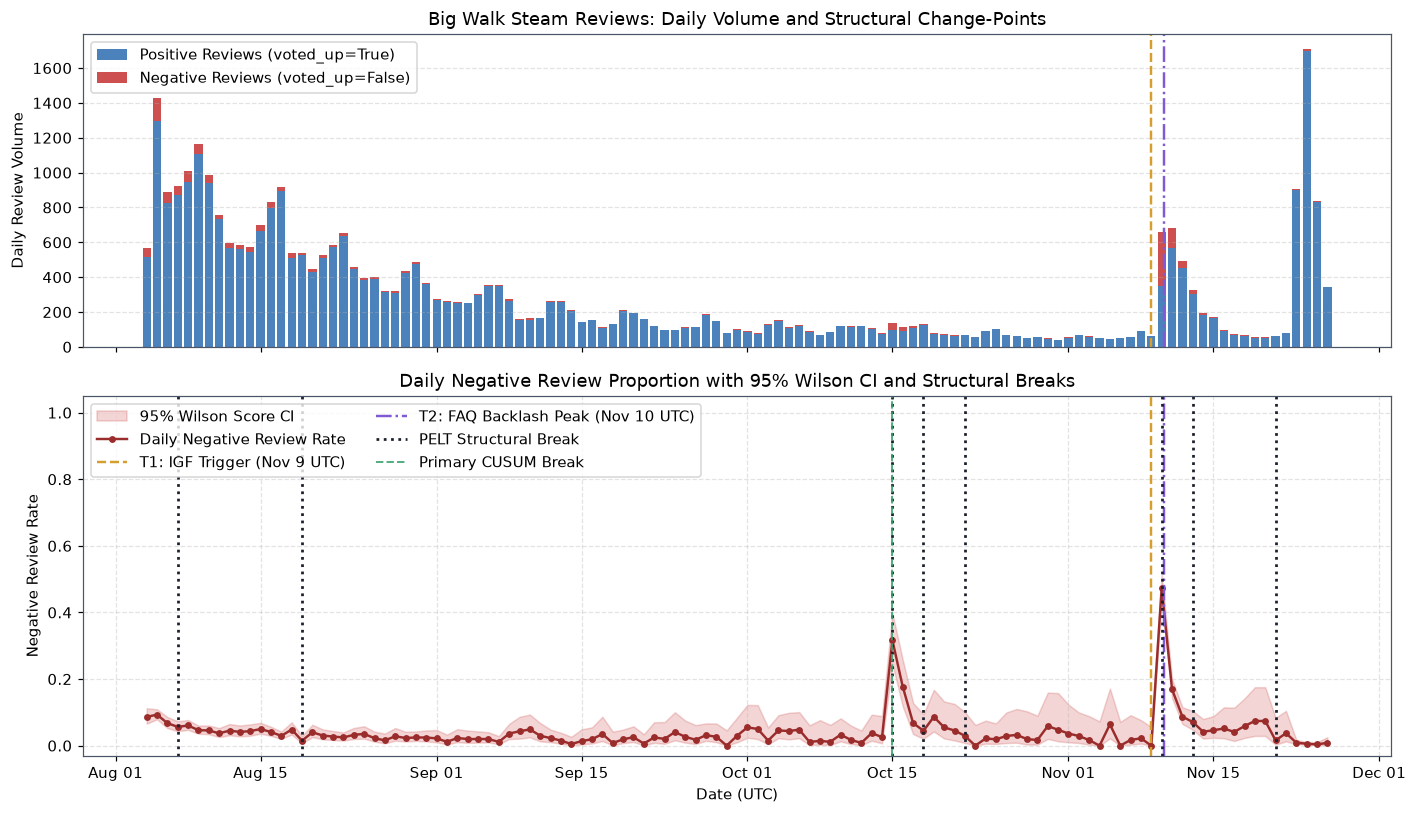

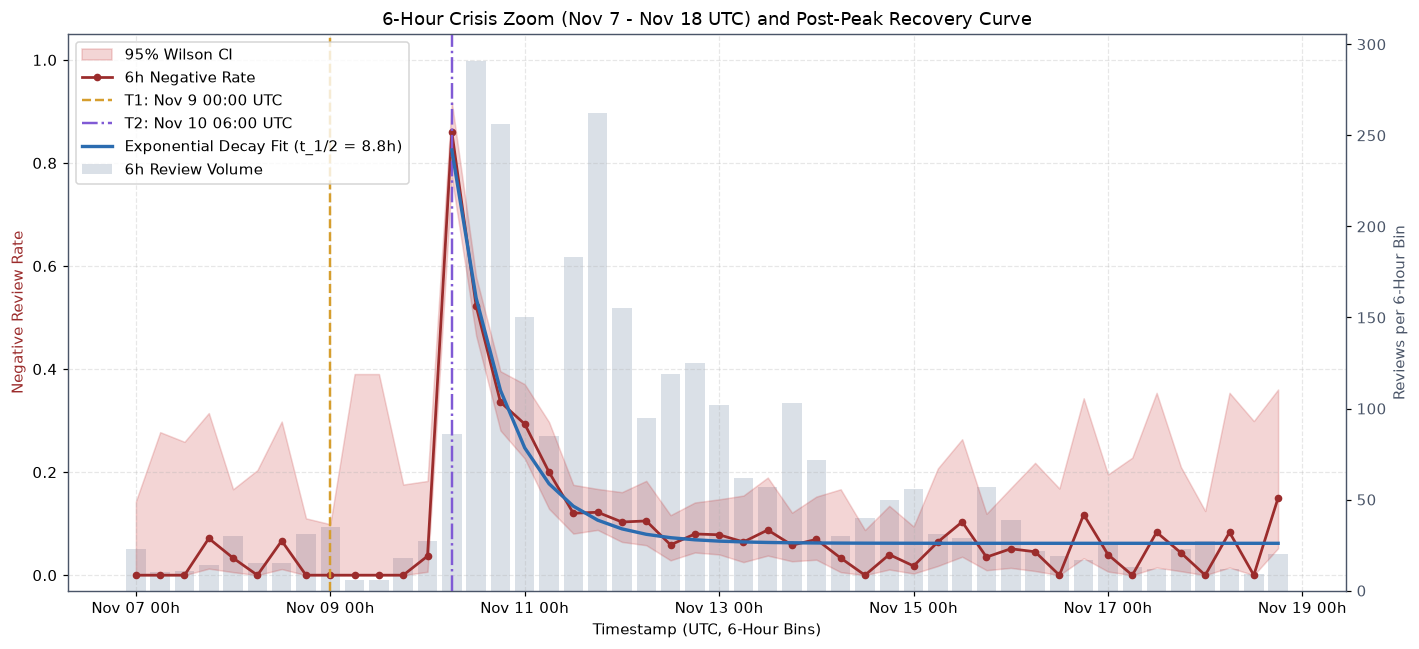

In [5]:
T1_IGF_TRIGGER_UTC = pd.Timestamp("2026-11-09 00:00:00+00:00")
T2_FAQ_PEAK_UTC = pd.Timestamp("2026-11-10 06:00:00+00:00")


def _ensure_utc_datetime(df: pd.DataFrame) -> pd.Series:
    if "created_utc" in df.columns:
        return pd.to_datetime(df["created_utc"], utc=True)
    if "timestamp_created" in df.columns:
        return pd.to_datetime(df["timestamp_created"], unit="s", utc=True)
    raise KeyError("DataFrame must contain 'created_utc' or 'timestamp_created'.")


def wilson_ci(
    k: np.ndarray | float | int,
    n: np.ndarray | float | int,
    z: float = 1.959963984540054,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    '''Compute proportion and 95% Wilson score confidence interval (vectorized).'''
    k_arr = np.asarray(k, dtype=np.float64)
    n_arr = np.asarray(n, dtype=np.float64)
    p_hat = np.zeros_like(n_arr, dtype=np.float64)
    ci_low = np.zeros_like(n_arr, dtype=np.float64)
    ci_high = np.zeros_like(n_arr, dtype=np.float64)

    valid = n_arr > 0.0
    if np.any(valid):
        kv = k_arr[valid]
        nv = n_arr[valid]
        p = np.clip(kv / nv, 0.0, 1.0)
        z2 = z * z
        denom = 1.0 + z2 / nv
        center = (p + z2 / (2.0 * nv)) / denom
        half = (z / denom) * np.sqrt((p * (1.0 - p)) / nv + z2 / (4.0 * nv * nv))
        p_hat[valid] = p
        ci_low[valid] = np.clip(center - half, 0.0, 1.0)
        ci_high[valid] = np.clip(center + half, 0.0, 1.0)
    return p_hat, ci_low, ci_high


def aggregate_time_series(
    df: pd.DataFrame,
    daily_start_utc: str = "2026-08-04 00:00:00+00:00",
    zoom_start_utc: str = "2026-11-07 00:00:00+00:00",
    zoom_end_utc: str = "2026-11-18 23:59:59+00:00",
) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''Aggregate Steam reviews into daily bins (Aug 4 onward) and 6-hour crisis bins (Nov 7-18 UTC).'''
    work = df.copy()
    work["_created_utc"] = _ensure_utc_datetime(work)
    work["_is_neg"] = (~work["voted_up"].astype(bool)).astype(int)
    work["_is_pos"] = work["voted_up"].astype(bool).astype(int)

    def _agg_bins(sub: pd.DataFrame, freq: str, start_ts: pd.Timestamp, end_ts: pd.Timestamp) -> pd.DataFrame:
        full_idx = pd.date_range(start=start_ts.floor(freq), end=end_ts.floor(freq), freq=freq, tz="UTC")
        if sub.empty:
            return pd.DataFrame(
                {
                    "bin_utc": full_idx,
                    "total_reviews": np.zeros(len(full_idx), dtype=int),
                    "negative_reviews": np.zeros(len(full_idx), dtype=int),
                    "positive_reviews": np.zeros(len(full_idx), dtype=int),
                    "neg_rate": np.zeros(len(full_idx), dtype=float),
                    "ci_low": np.zeros(len(full_idx), dtype=float),
                    "ci_high": np.zeros(len(full_idx), dtype=float),
                    "mean_vader": np.full(len(full_idx), np.nan, dtype=float),
                }
            )
        sub = sub.copy()
        sub["_bin"] = sub["_created_utc"].dt.floor(freq)
        grouped = sub.groupby("_bin", as_index=True).agg(
            total_reviews=("_is_neg", "count"),
            negative_reviews=("_is_neg", "sum"),
            positive_reviews=("_is_pos", "sum"),
            mean_vader=("vader_compound", "mean") if "vader_compound" in sub.columns else ("_is_neg", "mean"),
        ).reindex(full_idx)
        for col in ["total_reviews", "negative_reviews", "positive_reviews"]:
            grouped[col] = grouped[col].fillna(0).astype(int)
        neg_rate, ci_low, ci_high = wilson_ci(grouped["negative_reviews"].to_numpy(), grouped["total_reviews"].to_numpy())
        grouped["neg_rate"] = neg_rate
        grouped["ci_low"] = ci_low
        grouped["ci_high"] = ci_high
        return grouped.reset_index().rename(columns={"index": "bin_utc"})

    d_start = pd.Timestamp(daily_start_utc)
    if d_start.tzinfo is None:
        d_start = d_start.tz_localize("UTC")
    daily_sub = work[work["_created_utc"] >= d_start]
    d_end = daily_sub["_created_utc"].max() if not daily_sub.empty else d_start
    daily_df = _agg_bins(daily_sub, "1D", d_start, d_end)

    z_start = pd.Timestamp(zoom_start_utc)
    z_end = pd.Timestamp(zoom_end_utc)
    if z_start.tzinfo is None:
        z_start = z_start.tz_localize("UTC")
    if z_end.tzinfo is None:
        z_end = z_end.tz_localize("UTC")
    zoom_sub = work[(work["_created_utc"] >= z_start) & (work["_created_utc"] <= z_end)]
    zoom_6h_df = _agg_bins(zoom_sub, "6h", z_start, z_end)
    return daily_df, zoom_6h_df


def detect_changepoints_pelt(
    series: Iterable[float],
    model: str = "l2",
    penalty: float | None = None,
    min_size: int = 3,
    gamma: float | None = None,
) -> dict[str, Any]:
    '''Exact Pure-NumPy PELT (Pruned Exact Linear Time) structural change-point detection.'''
    y = np.asarray(list(series), dtype=np.float64)
    n = len(y)
    min_size = max(1, int(min_size))

    if n < 2 * min_size or np.allclose(y, y[0], equal_nan=True):
        return {
            "changepoints": [],
            "segments": [(0, n)],
            "penalty_used": 0.0 if penalty is None else float(penalty),
            "model": model,
            "cost": 0.0,
        }

    if np.any(np.isnan(y)):
        idx = np.arange(n)
        valid = ~np.isnan(y)
        y = np.interp(idx, idx[valid], y[valid]) if np.any(valid) else np.zeros(n)

    model_norm = model.lower().strip()
    if model_norm not in {"l2", "rbf"}:
        raise ValueError(f"Unsupported PELT model '{model}'.")

    if model_norm == "l2":
        s1 = np.concatenate(([0.0], np.cumsum(y)))
        s2 = np.concatenate(([0.0], np.cumsum(y * y)))

        def seg_cost(s: int, e: int) -> float:
            length = e - s
            if length <= 0:
                return 0.0
            diff_s1 = s1[e] - s1[s]
            return float(max(0.0, (s2[e] - s2[s]) - (diff_s1 * diff_s1) / length))

        if penalty is None:
            diffs = np.diff(y)
            mad_sigma = np.median(np.abs(diffs - np.median(diffs))) / (0.67448975 * np.sqrt(2.0))
            noise_var = max(mad_sigma * mad_sigma, 0.05 * float(np.var(y)), 1e-8)
            beta = float(2.5 * noise_var * np.log(max(n, 2)))
        else:
            beta = float(penalty)
    else:
        gamma_val = (1.0 / max(2.0 * float(np.var(y)), 1e-8)) if gamma is None else float(gamma)
        sq_dist = (y[:, None] - y[None, :]) ** 2
        k_mat = np.exp(-gamma_val * sq_dist)
        p_mat = np.zeros((n + 1, n + 1), dtype=np.float64)
        p_mat[1:, 1:] = np.cumsum(np.cumsum(k_mat, axis=0), axis=1)

        def seg_cost(s: int, e: int) -> float:
            length = e - s
            if length <= 0:
                return 0.0
            block_sum = p_mat[e, e] - p_mat[s, e] - p_mat[e, s] + p_mat[s, s]
            return float(max(0.0, length - block_sum / length))

        beta = float(0.6 * np.log(max(n, 2))) if penalty is None else float(penalty)

    F = np.full(n + 1, np.inf, dtype=np.float64)
    prev = np.full(n + 1, -1, dtype=int)
    F[0] = -beta
    candidates: list[int] = [0]

    for t in range(min_size, n + 1):
        new_cand = t - min_size
        if new_cand > 0 and np.isfinite(F[new_cand]) and new_cand not in candidates:
            candidates.append(new_cand)

        best_val = np.inf
        best_s = -1
        for s in candidates:
            if t - s < min_size:
                continue
            val = F[s] + seg_cost(s, t) + beta
            if val < best_val:
                best_val = val
                best_s = s
        F[t] = best_val
        prev[t] = best_s

        if new_cand >= 0 and np.isfinite(F[new_cand]):
            candidates = [
                s for s in candidates
                if s == new_cand or (F[s] + seg_cost(s, new_cand) <= F[new_cand] + 1e-12)
            ]

    splits: list[int] = []
    curr = n
    while curr > 0:
        p = int(prev[curr])
        if p <= 0:
            break
        splits.append(p)
        curr = p
    splits.sort()
    bounds = [0] + splits + [n]
    return {
        "changepoints": splits,
        "segments": [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)],
        "penalty_used": beta,
        "model": model_norm,
        "cost": float(F[n]),
    }


def detect_changepoints_cusum(
    series: Iterable[float],
    min_size: int = 3,
    bridge_threshold: float = 1.358,
    page_k: float = 0.5,
    page_h: float = 4.0,
) -> dict[str, Any]:
    '''Pure-NumPy CUSUM structural break detection (Brownian-Bridge + Page CUSUM).'''
    y = np.asarray(list(series), dtype=np.float64)
    n = len(y)
    if np.any(np.isnan(y)):
        idx = np.arange(n)
        valid = ~np.isnan(y)
        y = np.interp(idx, idx[valid], y[valid]) if np.any(valid) else np.zeros(n)

    if n < 2 * min_size or np.std(y) < 1e-12:
        return {
            "changepoints": [], "max_cusum_idx": None, "max_cusum_stat": 0.0,
            "p_value_approx": 1.0, "bridge_series": np.zeros(n),
            "page_pos": np.zeros(n), "page_neg": np.zeros(n), "page_alarms": [],
        }

    def _ks_bridge_pvalue(lam: float) -> float:
        if lam <= 0.0:
            return 1.0
        terms = [((-1.0) ** (k - 1)) * math.exp(-2.0 * (k * k) * (lam * lam)) for k in range(1, 20)]
        return float(np.clip(2.0 * sum(terms), 0.0, 1.0))

    def _segment_bridge(sub: np.ndarray) -> tuple[int, float, np.ndarray]:
        m = len(sub)
        centered = sub - np.mean(sub)
        sigma = float(np.std(sub, ddof=1)) if m > 1 else 0.0
        if sigma < 1e-12:
            return -1, 0.0, np.zeros(m, dtype=np.float64)
        cusum = np.cumsum(centered) / (sigma * math.sqrt(m))
        if m <= 2 * min_size:
            return -1, float(np.max(np.abs(cusum))), cusum
        abs_c = np.abs(cusum[min_size - 1 : m - min_size])
        rel_idx = int(np.argmax(abs_c)) + min_size
        return rel_idx, float(abs_c[rel_idx - min_size]), cusum

    _, global_stat, global_bridge = _segment_bridge(y)
    max_idx = int(np.argmax(np.abs(global_bridge))) + 1 if n > 0 else None
    p_val = _ks_bridge_pvalue(global_stat)

    detected: list[int] = []
    def _recurse(start: int, end: int) -> None:
        if end - start < 2 * min_size:
            return
        split_rel, stat, _ = _segment_bridge(y[start:end])
        if split_rel > 0 and stat >= bridge_threshold:
            split_abs = start + split_rel
            detected.append(split_abs)
            _recurse(start, split_abs)
            _recurse(split_abs, end)

    _recurse(0, n)
    detected = sorted(set(detected))

    base_len = max(min_size, min(n // 3, 14))
    mu0 = float(np.mean(y[:base_len]))
    sigma0 = float(np.std(y[:base_len], ddof=1)) if base_len > 1 else float(np.std(y))
    sigma0 = max(sigma0, float(np.std(y)) * 0.25, 1e-6)

    page_pos = np.zeros(n, dtype=np.float64)
    page_neg = np.zeros(n, dtype=np.float64)
    alarms: list[int] = []
    for i in range(n):
        z_i = (y[i] - mu0) / sigma0
        page_pos[i] = max(0.0, (page_pos[i - 1] if i > 0 else 0.0) + z_i - page_k)
        page_neg[i] = max(0.0, (page_neg[i - 1] if i > 0 else 0.0) - z_i - page_k)
        if page_pos[i] >= page_h or page_neg[i] >= page_h:
            alarms.append(i)

    return {
        "changepoints": detected, "max_cusum_idx": max_idx, "max_cusum_stat": global_stat,
        "p_value_approx": p_val, "bridge_series": global_bridge,
        "page_pos": page_pos, "page_neg": page_neg, "page_alarms": alarms,
    }


def evaluate_breaks_against_events(
    bin_timestamps: pd.Series,
    changepoint_indices: list[int],
    t1_utc: pd.Timestamp = T1_IGF_TRIGGER_UTC,
    t2_utc: pd.Timestamp = T2_FAQ_PEAK_UTC,
) -> pd.DataFrame:
    '''Compare detected changepoint indices against T1 (Nov 9) and T2 (Nov 10) timestamps.'''
    rows = []
    ts_list = pd.to_datetime(bin_timestamps, utc=True).reset_index(drop=True)
    for idx in changepoint_indices:
        if 0 <= idx < len(ts_list):
            bp_ts = ts_list.iloc[idx]
            rows.append(
                {
                    "changepoint_idx": int(idx),
                    "changepoint_utc": bp_ts,
                    "offset_from_T1_hrs": round((bp_ts - t1_utc).total_seconds() / 3600.0, 2),
                    "offset_from_T2_hrs": round((bp_ts - t2_utc).total_seconds() / 3600.0, 2),
                }
            )
    return pd.DataFrame(rows)


def compute_shock_summary(
    df: pd.DataFrame,
    daily_df: pd.DataFrame,
    zoom_6h_df: pd.DataFrame,
    t1_utc: pd.Timestamp = T1_IGF_TRIGGER_UTC,
    t2_utc: pd.Timestamp = T2_FAQ_PEAK_UTC,
    min_bin_reviews_for_peak: int = 5,
) -> tuple[pd.DataFrame, dict[str, Any]]:
    '''Compute quantitative shock and exponential decay recovery metrics.'''
    work = df.copy()
    work["_created_utc"] = _ensure_utc_datetime(work)
    work["_is_neg"] = (~work["voted_up"].astype(bool)).astype(int)

    pre = work[work["_created_utc"] < t1_utc]
    if len(pre) > 0:
        base_k = int(pre["_is_neg"].sum())
        base_n = int(len(pre))
        base_rate, base_low, base_high = wilson_ci(base_k, base_n)
        baseline_neg_rate = float(base_rate)
        baseline_ci = (float(base_low), float(base_high))
    else:
        baseline_neg_rate, baseline_ci, base_k, base_n = 0.0, (0.0, 0.0), 0, 0

    valid_6h = zoom_6h_df[zoom_6h_df["total_reviews"] >= min_bin_reviews_for_peak]
    if valid_6h.empty:
        valid_6h = zoom_6h_df[zoom_6h_df["total_reviews"] > 0]

    if valid_6h.empty:
        valid_daily = daily_df[daily_df["total_reviews"] > 0]
        peak_row = valid_daily.loc[valid_daily["neg_rate"].idxmax()]
        peak_source = "daily_fallback"
        post_bins = valid_daily[valid_daily["bin_utc"] >= peak_row["bin_utc"]].copy()
    else:
        peak_row = valid_6h.loc[valid_6h["neg_rate"].idxmax()]
        peak_source = "6h_crisis_zoom"
        post_bins = zoom_6h_df[
            (zoom_6h_df["bin_utc"] >= peak_row["bin_utc"]) & (zoom_6h_df["total_reviews"] > 0)
        ].copy()

    peak_neg_rate = float(peak_row["neg_rate"])
    peak_ci = (float(peak_row["ci_low"]), float(peak_row["ci_high"]))
    peak_utc = pd.Timestamp(peak_row["bin_utc"])
    if peak_utc.tzinfo is None:
        peak_utc = peak_utc.tz_localize("UTC")

    delta_neg_rate = peak_neg_rate - baseline_neg_rate
    crisis = work[work["_created_utc"] >= t1_utc]
    crisis_total = int(len(crisis))
    crisis_neg = int(crisis["_is_neg"].sum())
    expected_neg = baseline_neg_rate * crisis_total
    excess_neg_reviews = float(max(0.0, crisis_neg - expected_neg))

    onset_from_t1_hrs = (peak_utc - t1_utc).total_seconds() / 3600.0
    onset_from_t2_hrs = (peak_utc - t2_utc).total_seconds() / 3600.0

    decay_info: dict[str, Any] = {
        "fit_status": "not_fitted", "lambda_per_hr": np.nan, "half_life_hrs": np.nan,
        "r_inf": np.nan, "r0": peak_neg_rate, "t_hrs": np.array([]),
        "r_obs": np.array([]), "r_pred": np.array([]),
        "peak_utc": peak_utc, "peak_source": peak_source,
    }

    if len(post_bins) >= 4:
        t_hrs = (pd.to_datetime(post_bins["bin_utc"], utc=True) - peak_utc).dt.total_seconds().to_numpy() / 3600.0
        r_obs = post_bins["neg_rate"].to_numpy(dtype=np.float64)
        weights = np.sqrt(np.maximum(post_bins["total_reviews"].to_numpy(dtype=np.float64), 1.0))
        decay_info["t_hrs"], decay_info["r_obs"] = t_hrs, r_obs

        if r_obs[0] - r_obs[-1] <= 0.02:
            decay_info["fit_status"] = "fallback_no_observable_decay"
        else:
            def _exp_decay(t: np.ndarray, r_inf: float, amp: float, lam: float) -> np.ndarray:
                return r_inf + amp * np.exp(-lam * t)

            r_inf_init = float(np.clip(min(baseline_neg_rate, r_obs[-1]), 0.0, r_obs[0]))
            amp_init = float(max(r_obs[0] - r_inf_init, 0.05))
            try:
                popt, _ = optimize.curve_fit(
                    _exp_decay, t_hrs, r_obs,
                    p0=[r_inf_init, amp_init, 0.02],
                    sigma=1.0 / weights,
                    bounds=([0.0, 0.0, 1e-5], [min(1.0, r_obs[0]), 1.0, 2.0]),
                    maxfev=10000,
                )
                r_inf_hat, amp_hat, lam_hat = [float(v) for v in popt]
                if lam_hat > 1e-4:
                    decay_info.update({
                        "lambda_per_hr": lam_hat,
                        "half_life_hrs": math.log(2.0) / lam_hat,
                        "r_inf": r_inf_hat,
                        "r0": r_inf_hat + amp_hat,
                        "r_pred": _exp_decay(t_hrs, r_inf_hat, amp_hat, lam_hat),
                        "fit_status": "converged",
                    })
                else:
                    decay_info["fit_status"] = "fallback_near_zero_lambda"
            except (RuntimeError, ValueError, TypeError):
                decay_info["fit_status"] = "fallback_curve_fit_failed"
    else:
        decay_info["fit_status"] = "fallback_short_recovery_window"

    summary_rows = [
        {"metric": "Baseline_NegRate_PreT1", "value": round(baseline_neg_rate, 4), "detail": f"k={base_k}/n={base_n}, 95% CI [{baseline_ci[0]:.3f}, {baseline_ci[1]:.3f}]"},
        {"metric": "Peak_NegRate", "value": round(peak_neg_rate, 4), "detail": f"UTC={peak_utc.isoformat()} ({peak_source}), 95% CI [{peak_ci[0]:.3f}, {peak_ci[1]:.3f}]"},
        {"metric": "Shock_Magnitude_DeltaNegRate", "value": round(delta_neg_rate, 4), "detail": "Peak_NegRate - Baseline_NegRate_PreT1"},
        {"metric": "Excess_Negative_Reviews", "value": round(excess_neg_reviews, 1), "detail": f"Observed crisis neg={crisis_neg} vs baseline expected={expected_neg:.1f} (N={crisis_total})"},
        {"metric": "Onset_Velocity_From_T1_Hrs", "value": round(onset_from_t1_hrs, 2), "detail": f"Hours from T1 ({t1_utc.strftime('%Y-%m-%d %H:%M UTC')}) to peak"},
        {"metric": "Onset_Velocity_From_T2_Hrs", "value": round(onset_from_t2_hrs, 2), "detail": f"Hours from T2 ({t2_utc.strftime('%Y-%m-%d %H:%M UTC')}) to peak"},
        {"metric": "Decay_Lambda_Per_Hr", "value": round(decay_info["lambda_per_hr"], 5) if np.isfinite(decay_info["lambda_per_hr"]) else np.nan, "detail": f"Status: {decay_info['fit_status']}"},
        {"metric": "Recovery_Half_Life_Hrs", "value": round(decay_info["half_life_hrs"], 2) if np.isfinite(decay_info["half_life_hrs"]) else np.nan, "detail": "t_1/2 = ln(2) / lambda"},
    ]
    return pd.DataFrame(summary_rows), decay_info


def plot_daily_shock_timeline(
    daily_df: pd.DataFrame,
    pelt_result: dict[str, Any],
    cusum_result: dict[str, Any],
    t1_utc: pd.Timestamp = T1_IGF_TRIGGER_UTC,
    t2_utc: pd.Timestamp = T2_FAQ_PEAK_UTC,
    figsize: tuple[float, float] = (13.0, 7.5),
) -> plt.Figure:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize, sharex=True, gridspec_kw={"height_ratios": [1.0, 1.15]})
    dates = pd.to_datetime(daily_df["bin_utc"], utc=True)
    pos = daily_df["positive_reviews"].to_numpy()
    neg = daily_df["negative_reviews"].to_numpy()

    ax1.bar(dates, pos, width=0.8, color="#2b6cb0", alpha=0.85, label="Positive Reviews (voted_up=True)")
    ax1.bar(dates, neg, bottom=pos, width=0.8, color="#c53030", alpha=0.85, label="Negative Reviews (voted_up=False)")
    ax1.set_ylabel("Daily Review Volume")
    ax1.set_title("Big Walk Steam Reviews: Daily Volume and Structural Change-Points")
    ax1.grid(axis="y", linestyle="--", alpha=0.35)

    has_reviews = daily_df["total_reviews"].to_numpy() > 0
    ax2.fill_between(dates[has_reviews], daily_df["ci_low"].to_numpy()[has_reviews], daily_df["ci_high"].to_numpy()[has_reviews], color="#c53030", alpha=0.20, label="95% Wilson Score CI")
    ax2.plot(dates[has_reviews], daily_df["neg_rate"].to_numpy()[has_reviews], color="#9b2c2c", marker="o", markersize=3.5, linewidth=1.6, label="Daily Negative Review Rate")

    for ax in (ax1, ax2):
        ax.axvline(t1_utc, color="#d69e2e", linestyle="--", linewidth=1.6, label="T1: IGF Trigger (Nov 9 UTC)" if ax is ax2 else None)
        ax.axvline(t2_utc, color="#805ad5", linestyle="-.", linewidth=1.6, label="T2: FAQ Backlash Peak (Nov 10 UTC)" if ax is ax2 else None)

    for i, bp_idx in enumerate(pelt_result.get("changepoints", [])):
        if 0 <= bp_idx < len(dates):
            ax2.axvline(dates.iloc[bp_idx], color="#1a202c", linestyle=":", linewidth=1.8, label="PELT Structural Break" if i == 0 else None)

    cusum_idx = cusum_result.get("max_cusum_idx")
    if cusum_idx is not None and 0 <= cusum_idx < len(dates):
        ax2.axvline(dates.iloc[cusum_idx], color="#38a169", linestyle="--", linewidth=1.3, alpha=0.85, label="Primary CUSUM Break")

    ax2.set_ylim(-0.03, 1.05)
    ax2.set_ylabel("Negative Review Rate")
    ax2.set_xlabel("Date (UTC)")
    ax2.set_title("Daily Negative Review Proportion with 95% Wilson CI and Structural Breaks")
    ax2.grid(True, linestyle="--", alpha=0.35)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax1.legend(loc="upper left", frameon=True)
    ax2.legend(loc="upper left", frameon=True, ncol=2)
    fig.tight_layout()
    return fig


def plot_crisis_zoom_and_decay(
    zoom_6h_df: pd.DataFrame,
    decay_info: dict[str, Any],
    t1_utc: pd.Timestamp = T1_IGF_TRIGGER_UTC,
    t2_utc: pd.Timestamp = T2_FAQ_PEAK_UTC,
    figsize: tuple[float, float] = (13.0, 6.0),
) -> plt.Figure:
    fig, ax_rate = plt.subplots(figsize=figsize)
    ax_vol = ax_rate.twinx()

    bins = pd.to_datetime(zoom_6h_df["bin_utc"], utc=True)
    total = zoom_6h_df["total_reviews"].to_numpy()
    valid = total > 0

    ax_vol.bar(bins, total, width=0.20, color="#a0aec0", alpha=0.38, label="6h Review Volume")
    ax_vol.set_ylabel("Reviews per 6-Hour Bin", color="#4a5568")
    ax_vol.tick_params(axis="y", labelcolor="#4a5568")

    ax_rate.fill_between(bins[valid], zoom_6h_df["ci_low"].to_numpy()[valid], zoom_6h_df["ci_high"].to_numpy()[valid], color="#c53030", alpha=0.20, label="95% Wilson CI")
    ax_rate.plot(bins[valid], zoom_6h_df["neg_rate"].to_numpy()[valid], color="#9b2c2c", marker="o", markersize=4, linewidth=1.8, label="6h Negative Rate")
    ax_rate.axvline(t1_utc, color="#d69e2e", linestyle="--", linewidth=1.6, label="T1: Nov 9 00:00 UTC")
    ax_rate.axvline(t2_utc, color="#805ad5", linestyle="-.", linewidth=1.6, label="T2: Nov 10 06:00 UTC")

    if decay_info.get("fit_status") == "converged" and len(decay_info.get("r_pred", [])) > 0:
        peak_utc = decay_info["peak_utc"]
        decay_dates = [peak_utc + pd.Timedelta(hours=float(h)) for h in decay_info["t_hrs"]]
        ax_rate.plot(
            decay_dates, decay_info["r_pred"], color="#2b6cb0", linestyle="-", linewidth=2.2,
            label=f"Exponential Decay Fit (t_1/2 = {decay_info['half_life_hrs']:.1f}h)",
        )
    else:
        ax_rate.text(
            0.98, 0.94, f"Decay fit note: {decay_info.get('fit_status', 'unavailable')}",
            transform=ax_rate.transAxes, ha="right", va="top", fontsize=9,
            bbox={"boxstyle": "round", "facecolor": "#edf2f7", "edgecolor": "#cbd5e0"},
        )

    ax_rate.set_ylim(-0.03, 1.05)
    ax_rate.set_ylabel("Negative Review Rate", color="#9b2c2c")
    ax_rate.set_xlabel("Timestamp (UTC, 6-Hour Bins)")
    ax_rate.set_title("6-Hour Crisis Zoom (Nov 7 - Nov 18 UTC) and Post-Peak Recovery Curve")
    ax_rate.xaxis.set_major_formatter(mdates.DateFormatter("%b %d %Hh"))
    ax_rate.grid(True, linestyle="--", alpha=0.30)

    lines1, labels1 = ax_rate.get_legend_handles_labels()
    lines2, labels2 = ax_vol.get_legend_handles_labels()
    ax_rate.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True)
    ax_rate.set_zorder(ax_vol.get_zorder() + 1)
    ax_rate.patch.set_visible(False)
    fig.tight_layout()
    return fig


daily_df, zoom_6h_df = aggregate_time_series(df_clean)
pelt_l2 = detect_changepoints_pelt(daily_df["neg_rate"], model="l2", min_size=3)
pelt_rbf = detect_changepoints_pelt(daily_df["neg_rate"], model="rbf", min_size=3)
cusum_daily = detect_changepoints_cusum(daily_df["neg_rate"], min_size=3)

# Also run 6-hour zoom PELT & CUSUM for sub-day structural timing precision
pelt_6h_l2 = detect_changepoints_pelt(zoom_6h_df["neg_rate"], model="l2", min_size=3)
cusum_6h = detect_changepoints_cusum(zoom_6h_df["neg_rate"], min_size=3)

shock_summary_df, decay_info = compute_shock_summary(df_clean, daily_df, zoom_6h_df)
print("Chapter 4A Quantitative Shock & Recovery Summary:")
print(shock_summary_df.to_string(index=False))

print("\nDaily PELT (L2) Change-Points vs T1/T2:")
print(evaluate_breaks_against_events(daily_df["bin_utc"], pelt_l2["changepoints"]).to_string(index=False))
print("\nDaily PELT (RBF) Change-Points vs T1/T2:")
print(evaluate_breaks_against_events(daily_df["bin_utc"], pelt_rbf["changepoints"]).to_string(index=False))
print(f"\nDaily CUSUM global max stat={cusum_daily['max_cusum_stat']:.3f}, p_approx={cusum_daily['p_value_approx']:.4e}, breaks={cusum_daily['changepoints']}")
print("6-Hour Crisis Zoom PELT (L2) Change-Points vs T1/T2:")
print(evaluate_breaks_against_events(zoom_6h_df["bin_utc"], pelt_6h_l2["changepoints"]).to_string(index=False))

fig_daily = plot_daily_shock_timeline(daily_df, pelt_l2, cusum_daily)
plt.show()
plt.close(fig_daily)

fig_zoom = plot_crisis_zoom_and_decay(zoom_6h_df, decay_info)
plt.show()
plt.close(fig_zoom)

---
## Chapter 4B: Gold Labeling Checkpoint, Stance Classification Ablation & Sentiment Divergence

### Supervised Stance Taxonomy & Checkpoint Protocol
Reviews are classified into three mutually exclusive communicative intents:
- `Gameplay_Genuine`: Organic gameplay evaluation unrelated to the November 2026 controversy.
- `Anti_AI_Backlash`: Criticism, boycott, or disqualification claims targeting alleged generative AI usage or disclosure.
- `Pro_Dev_Clarification`: Defense of House House, citation of technical FAQ scope (`0_1_percent`, `10_lines`, `shadow_caster`), or pushback against `review_bomb` activity.

### Leak-Free Ablation Protocol
- **Held-Out Split**: `StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)` isolates a locked 30% Held-Out Test Set.
- **Inner Tuning**: `GridSearchCV(..., cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='f1_macro')` runs exclusively on the 70% Train Set across 3 classical models (`CalibratedClassifierCV(LinearSVC)`, `MultinomialNB`, `LogisticRegression`) $\times$ 2 feature regimes (`Text_Only` vs `Multimodal`).
- **Non-Negativity Invariant**: `MultinomialNB` pipelines enforce `X_train_nb.min() >= 0.0` and `X_test_nb.min() >= 0.0` via `NonNegativeShift` + `MinMaxScaler((0, 1), clip=True)` fitted strictly inside each training fold.

[WARNING] ALLOW_PRELABEL_DRYRUN=True: Using heuristic 'suggested_label'
from 'D:\05-Dev\Colab\DataMining-Project\data\annotation\annotation_candidates.csv' because 'D:\05-Dev\Colab\DataMining-Project\data\annotation\gold_labels.csv' is not populated.
Metrics in this run represent a prelabel dry-run, NOT human-verified truth.
Labeling Mode: PRELABEL_DRYRUN | Labeled Rows: 390
stance_label
Pro_Dev_Clarification    130
Anti_AI_Backlash         130
Gameplay_Genuine         130

Train rows: 273 | Held-Out Test rows: 117 | Inner CV folds: 5
MultinomialNB Non-Negativity Checks: {'Text_Only': {'train_min': 0.0, 'test_min': 0.0}, 'Multimodal': {'train_min': 0.0, 'test_min': 0.0}}
Best Multimodal Model: ('Multimodal', 'LogisticRegression')

Full-Corpus Predicted Stance Counts:
predicted_stance
Gameplay_Genuine         27726
Pro_Dev_Clarification     4572
Anti_AI_Backlash          2068

VADER vs Steam Vote Divergence by Predicted Stance:
     predicted_stance  total_reviews  pos_vote_count  pos_v

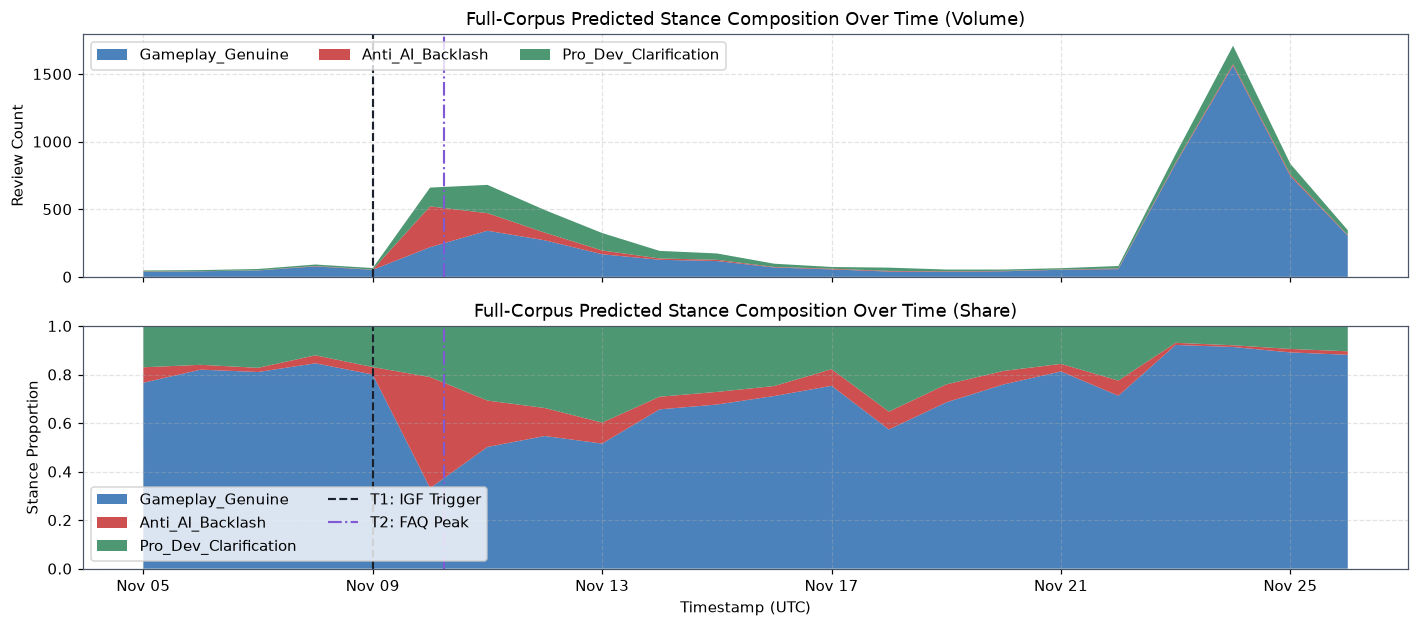

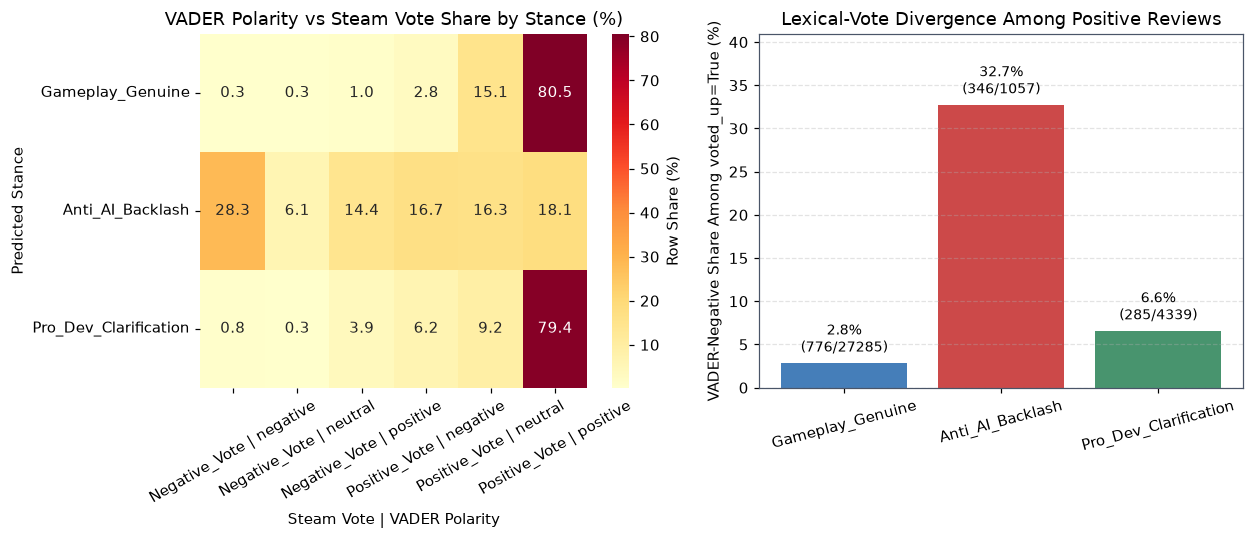

In [6]:
STANCE_CLASSES = [
    "Gameplay_Genuine",
    "Anti_AI_Backlash",
    "Pro_Dev_Clarification",
]


def holm_bonferroni_adjust(raw_p_values: Iterable[float]) -> np.ndarray:
    '''Pure-NumPy step-down Holm-Bonferroni p-value adjustment.'''
    p = np.asarray(list(raw_p_values), dtype=np.float64)
    m = len(p)
    if m == 0:
        return p
    order = np.argsort(p)
    adj = np.empty(m, dtype=np.float64)
    prev_adj = 0.0
    for rank_idx, orig_idx in enumerate(order):
        val = min(1.0, max(prev_adj, (m - rank_idx) * p[orig_idx]))
        adj[orig_idx] = val
        prev_adj = val
    return adj


def load_annotation_checkpoint(
    annotation_dir: str | Path,
    clean_df: pd.DataFrame | None = None,
    allow_prelabel_dryrun: bool = True,
    gold_filename: str = "gold_labels.csv",
    candidates_filename: str = "annotation_candidates.csv",
) -> tuple[pd.DataFrame, str]:
    '''Load labeled stance data using GOLD_VERIFIED mode or ALLOW_PRELABEL_DRYRUN mode.'''
    ann_path = Path(annotation_dir)
    gold_path = ann_path / gold_filename
    cand_path = ann_path / candidates_filename

    mode = ""
    raw_ann: pd.DataFrame | None = None

    if gold_path.exists():
        gdf = pd.read_csv(gold_path)
        if "gold_label" in gdf.columns:
            valid_gold = gdf[gdf["gold_label"].isin(STANCE_CLASSES)].copy()
            if len(valid_gold) >= 30:
                valid_gold["stance_label"] = valid_gold["gold_label"].astype(str)
                raw_ann = valid_gold
                mode = "GOLD_VERIFIED"

    if raw_ann is None:
        if not allow_prelabel_dryrun:
            raise FileNotFoundError(f"Verified gold labels not found at '{gold_path}' and allow_prelabel_dryrun=False.")
        if not cand_path.exists():
            raise FileNotFoundError(f"Neither '{gold_path}' nor '{cand_path}' exists.")
        cdf = pd.read_csv(cand_path)
        if "gold_label" in cdf.columns and cdf["gold_label"].isin(STANCE_CLASSES).sum() >= 30:
            raw_ann = cdf[cdf["gold_label"].isin(STANCE_CLASSES)].copy()
            raw_ann["stance_label"] = raw_ann["gold_label"].astype(str)
            mode = "GOLD_VERIFIED"
        else:
            print("=" * 80)
            print("[WARNING] ALLOW_PRELABEL_DRYRUN=True: Using heuristic 'suggested_label'")
            print(f"from '{cand_path}' because '{gold_path}' is not populated.")
            print("Metrics in this run represent a prelabel dry-run, NOT human-verified truth.")
            print("=" * 80)
            raw_ann = cdf.copy()
            if "gold_label" in raw_ann.columns:
                has_gold = raw_ann["gold_label"].isin(STANCE_CLASSES)
                raw_ann["stance_label"] = np.where(has_gold, raw_ann["gold_label"], raw_ann["suggested_label"])
            else:
                raw_ann["stance_label"] = raw_ann["suggested_label"]
            raw_ann = raw_ann[raw_ann["stance_label"].isin(STANCE_CLASSES)].copy()
            mode = "PRELABEL_DRYRUN"

    if clean_df is not None and "recommendationid" in raw_ann.columns and "recommendationid" in clean_df.columns:
        raw_ann["recommendationid"] = raw_ann["recommendationid"].astype(str)
        clean_lookup = clean_df.copy()
        clean_lookup["recommendationid"] = clean_lookup["recommendationid"].astype(str)
        missing_cols = [c for c in clean_lookup.columns if c not in raw_ann.columns and c != "recommendationid"]
        if missing_cols:
            raw_ann = raw_ann.merge(clean_lookup[["recommendationid"] + missing_cols], on="recommendationid", how="left")

    raw_ann["text_clean"] = raw_ann["text_clean"].fillna("").astype(str)
    return raw_ann.reset_index(drop=True), mode


def _prepare_model_dataframe(df: pd.DataFrame, behavioral_cols: list[str]) -> pd.DataFrame:
    out = df.copy()
    out["text_clean"] = out["text_clean"].fillna("").astype(str)
    for col in behavioral_cols:
        if col not in out.columns:
            raise KeyError(f"Missing behavioral metadata column '{col}'.")
        out[col] = pd.to_numeric(out[col], errors="coerce").astype(np.float64)
    return out


def run_stance_ablation_suite(
    labeled_df: pd.DataFrame,
    behavioral_cols: list[str] | None = None,
    test_size: float = 0.30,
    random_state: int = RANDOM_SEED,
) -> dict[str, Any]:
    '''Train and evaluate SVM, MultinomialNB, and LogisticRegression across Text_Only and Multimodal.'''
    cols = [c for c in (behavioral_cols or BEHAVIORAL_FEATURES) if c in labeled_df.columns]
    work = _prepare_model_dataframe(labeled_df, cols)
    y_all = work["stance_label"].astype(str).to_numpy()

    splitter = StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(splitter.split(work, y_all))
    train_df = work.iloc[train_idx].reset_index(drop=True)
    test_df = work.iloc[test_idx].reset_index(drop=True)
    y_train, y_test = y_all[train_idx], y_all[test_idx]

    _, counts = np.unique(y_train, return_counts=True)
    min_class_count = int(counts.min())
    n_cv_splits = min(5, min_class_count)
    cal_cv_splits = min(3, min_class_count)
    cv_inner = StratifiedKFold(n_splits=n_cv_splits, shuffle=True, random_state=random_state)

    model_specs = {
        "SVM": (
            lambda: CalibratedClassifierCV(
                estimator=LinearSVC(class_weight="balanced", random_state=random_state, max_iter=5000),
                cv=cal_cv_splits,
            ),
            {"clf__estimator__C": [0.1, 1.0, 5.0, 10.0]},
        ),
        "MultinomialNB": (
            lambda: MultinomialNB(),
            {"clf__alpha": [0.05, 0.1, 0.5, 1.0, 2.0]},
        ),
        "LogisticRegression": (
            lambda: LogisticRegression(class_weight="balanced", max_iter=2000, random_state=random_state),
            {"clf__C": [0.1, 1.0, 5.0, 10.0]},
        ),
    }

    results: dict[tuple[str, str], dict[str, Any]] = {}
    nb_min_checks: dict[str, dict[str, float]] = {}

    for regime in ["Text_Only", "Multimodal"]:
        for model_name, (estimator_fn, param_grid) in model_specs.items():
            preprocessor = build_feature_preprocessor(regime=regime, model_name=model_name, behavioral_cols=cols)
            pipe = Pipeline([("preprocessor", preprocessor), ("clf", estimator_fn())])
            grid = GridSearchCV(
                estimator=pipe, param_grid=param_grid, cv=cv_inner,
                scoring="f1_macro", refit=True, n_jobs=1,
            )
            grid.fit(train_df, y_train)
            best_pipe = grid.best_estimator_

            if model_name == "MultinomialNB":
                fitted_prep = best_pipe.named_steps["preprocessor"]
                X_train_nb = fitted_prep.transform(train_df)
                X_test_nb = fitted_prep.transform(test_df)
                train_min, test_min = float(X_train_nb.min()), float(X_test_nb.min())
                assert train_min >= 0.0, f"MultinomialNB negative train feature: {train_min}"
                assert test_min >= 0.0, f"MultinomialNB negative test feature: {test_min}"
                nb_min_checks[regime] = {"train_min": train_min, "test_min": test_min}

            y_pred = best_pipe.predict(test_df)
            y_proba = best_pipe.predict_proba(test_df)
            results[(regime, model_name)] = {
                "regime": regime,
                "model": model_name,
                "estimator": best_pipe,
                "best_params": grid.best_params_,
                "cv_macro_f1": float(grid.best_score_),
                "y_test": y_test,
                "y_pred": y_pred,
                "y_proba": y_proba,
                "classes": list(best_pipe.classes_),
                "test_macro_f1": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
                "test_accuracy": float(accuracy_score(y_test, y_pred)),
            }

    mm_keys = [k for k in results if k[0] == "Multimodal"]
    best_mm_key = max(mm_keys, key=lambda k: (results[k]["test_macro_f1"], results[k]["cv_macro_f1"]))
    return {
        "results": results,
        "best_multimodal_key": best_mm_key,
        "best_multimodal_estimator": results[best_mm_key]["estimator"],
        "train_df": train_df,
        "test_df": test_df,
        "y_train": y_train,
        "y_test": y_test,
        "behavioral_cols": cols,
        "nb_min_checks": nb_min_checks,
        "cv_folds": n_cv_splits,
    }


def infer_corpus_stances(
    clean_df: pd.DataFrame,
    estimator: Pipeline,
    behavioral_cols: list[str] | None = None,
) -> pd.DataFrame:
    cols = [c for c in (behavioral_cols or BEHAVIORAL_FEATURES) if c in clean_df.columns]
    prepared = _prepare_model_dataframe(clean_df, cols)
    preds = estimator.predict(prepared)
    proba = estimator.predict_proba(prepared)
    classes = list(estimator.classes_)
    out = clean_df.copy()
    out["predicted_stance"] = preds
    for idx, cls_name in enumerate(classes):
        out[f"prob_{cls_name}"] = proba[:, idx]
    return out


def plot_stacked_stance_timeseries(
    corpus_df: pd.DataFrame,
    freq: str = "1D",
    start_utc: str = "2026-11-05 00:00:00+00:00",
    end_utc: str | None = None,
    t1_utc: pd.Timestamp = T1_IGF_TRIGGER_UTC,
    t2_utc: pd.Timestamp = T2_FAQ_PEAK_UTC,
    figsize: tuple[float, float] = (13.0, 5.8),
) -> tuple[plt.Figure, pd.DataFrame]:
    work = corpus_df.copy()
    work["_created_utc"] = _ensure_utc_datetime(work)
    start_ts = pd.Timestamp(start_utc)
    if start_ts.tzinfo is None:
        start_ts = start_ts.tz_localize("UTC")
    work = work[work["_created_utc"] >= start_ts]
    if end_utc is not None:
        end_ts = pd.Timestamp(end_utc)
        if end_ts.tzinfo is None:
            end_ts = end_ts.tz_localize("UTC")
        work = work[work["_created_utc"] <= end_ts]

    work["_bin"] = work["_created_utc"].dt.floor(freq)
    counts = (
        work.groupby(["_bin", "predicted_stance"]).size().unstack(fill_value=0)
        .reindex(columns=STANCE_CLASSES, fill_value=0).sort_index()
    )

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize, sharex=True)
    colors = {"Gameplay_Genuine": "#2b6cb0", "Anti_AI_Backlash": "#c53030", "Pro_Dev_Clarification": "#2f855a"}
    x = counts.index
    ax1.stackplot(x, [counts[c].to_numpy(dtype=float) for c in STANCE_CLASSES], labels=STANCE_CLASSES, colors=[colors[c] for c in STANCE_CLASSES], alpha=0.85)
    ax1.set_ylabel("Review Count")
    ax1.set_title("Full-Corpus Predicted Stance Composition Over Time (Volume)")
    ax1.grid(True, linestyle="--", alpha=0.35)

    totals = np.maximum(counts.sum(axis=1).to_numpy(dtype=float), 1.0)
    ax2.stackplot(x, [counts[c].to_numpy(dtype=float) / totals for c in STANCE_CLASSES], labels=STANCE_CLASSES, colors=[colors[c] for c in STANCE_CLASSES], alpha=0.85)
    ax2.set_ylabel("Stance Proportion")
    ax2.set_ylim(0.0, 1.0)
    ax2.set_xlabel("Timestamp (UTC)")
    ax2.set_title("Full-Corpus Predicted Stance Composition Over Time (Share)")
    ax2.grid(True, linestyle="--", alpha=0.35)

    for ax in (ax1, ax2):
        ax.axvline(t1_utc, color="#1a202c", linestyle="--", linewidth=1.4, label="T1: IGF Trigger" if ax is ax2 else None)
        ax.axvline(t2_utc, color="#805ad5", linestyle="-.", linewidth=1.4, label="T2: FAQ Peak" if ax is ax2 else None)

    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax1.legend(loc="upper left", frameon=True, ncol=3)
    ax2.legend(loc="lower left", frameon=True, ncol=2)
    fig.tight_layout()
    return fig, counts.reset_index().rename(columns={"_bin": "bin_utc"})


def analyze_vader_vote_divergence(
    corpus_df: pd.DataFrame,
    vader_neg_threshold: float = -0.05,
    figsize: tuple[float, float] = (11.5, 5.0),
) -> tuple[pd.DataFrame, dict[str, Any], plt.Figure]:
    work = corpus_df.copy()
    work["vote_str"] = np.where(work["voted_up"].astype(bool), "Positive_Vote", "Negative_Vote")
    work["vader_polarity"] = work["vader_label"].astype(str).str.lower() if "vader_label" in work.columns else np.where(
        work["vader_compound"] <= vader_neg_threshold, "negative",
        np.where(work["vader_compound"] >= 0.05, "positive", "neutral"),
    )
    crosstab_df = pd.crosstab([work["predicted_stance"], work["vote_str"]], work["vader_polarity"], margins=True)

    stance_rows = []
    for stance in STANCE_CLASSES:
        sub = work[work["predicted_stance"] == stance]
        pos_vote = sub[sub["voted_up"].astype(bool)]
        neg_vote = sub[~sub["voted_up"].astype(bool)]
        pos_vote_neg_vader = int((pos_vote["vader_compound"] <= vader_neg_threshold).sum())
        neg_vote_pos_vader = int((neg_vote["vader_compound"] >= 0.05).sum())
        stance_rows.append(
            {
                "predicted_stance": stance,
                "total_reviews": len(sub),
                "pos_vote_count": int(len(pos_vote)),
                "pos_vote_vader_neg_count": pos_vote_neg_vader,
                "pos_vote_vader_neg_pct": round(100.0 * pos_vote_neg_vader / len(pos_vote), 2) if len(pos_vote) > 0 else 0.0,
                "neg_vote_vader_pos_count": neg_vote_pos_vader,
                "mean_vader_compound": round(float(sub["vader_compound"].mean()), 4) if len(sub) > 0 else np.nan,
            }
        )
    stance_summary_df = pd.DataFrame(stance_rows)
    pro_dev_row = stance_summary_df[stance_summary_df["predicted_stance"] == "Pro_Dev_Clarification"].iloc[0]
    summary_dict = {
        "stance_divergence_table": stance_summary_df,
        "pro_dev_pos_vote_count": int(pro_dev_row["pos_vote_count"]),
        "pro_dev_pos_vote_vader_neg_count": int(pro_dev_row["pos_vote_vader_neg_count"]),
        "pro_dev_pos_vote_vader_neg_pct": float(pro_dev_row["pos_vote_vader_neg_pct"]),
        "overall_pos_vote_vader_neg_pct": round(
            100.0 * float((work[work["voted_up"].astype(bool)]["vader_compound"] <= vader_neg_threshold).mean()), 2
        ),
    }

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    heat_data = pd.crosstab(work["predicted_stance"], work["vote_str"] + " | " + work["vader_polarity"], normalize="index").reindex(index=STANCE_CLASSES) * 100.0
    sns.heatmap(heat_data, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax1, cbar_kws={"label": "Row Share (%)"})
    ax1.set_title("VADER Polarity vs Steam Vote Share by Stance (%)")
    ax1.set_xlabel("Steam Vote | VADER Polarity")
    ax1.set_ylabel("Predicted Stance")
    ax1.tick_params(axis="x", rotation=30)

    bars = ax2.bar(stance_summary_df["predicted_stance"], stance_summary_df["pos_vote_vader_neg_pct"], color=["#2b6cb0", "#c53030", "#2f855a"], alpha=0.88)
    for bar, cnt, tot in zip(bars, stance_summary_df["pos_vote_vader_neg_count"], stance_summary_df["pos_vote_count"]):
        ax2.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height() + 0.8, f"{bar.get_height():.1f}%\n({cnt}/{tot})", ha="center", va="bottom", fontsize=9)
    ax2.set_ylim(0, max(stance_summary_df["pos_vote_vader_neg_pct"].max() * 1.25, 15.0))
    ax2.set_ylabel("VADER-Negative Share Among voted_up=True (%)")
    ax2.set_title("Lexical-Vote Divergence Among Positive Reviews")
    ax2.tick_params(axis="x", rotation=15)
    ax2.grid(axis="y", linestyle="--", alpha=0.35)
    fig.tight_layout()
    return crosstab_df, summary_dict, fig


def compare_playtime_across_stances(
    corpus_df: pd.DataFrame,
    playtime_col: str = "playtime_at_review_hrs",
) -> dict[str, Any]:
    groups = {}
    summary_rows = []
    for stance in STANCE_CLASSES:
        vals = pd.to_numeric(corpus_df.loc[corpus_df["predicted_stance"] == stance, playtime_col], errors="coerce").dropna().to_numpy(dtype=np.float64)
        groups[stance] = vals
        summary_rows.append(
            {
                "predicted_stance": stance,
                "n": int(len(vals)),
                "median_hrs": round(float(np.median(vals)), 3) if len(vals) > 0 else np.nan,
                "iqr_hrs": round(float(np.percentile(vals, 75) - np.percentile(vals, 25)), 3) if len(vals) > 0 else np.nan,
                "mean_hrs": round(float(np.mean(vals)), 3) if len(vals) > 0 else np.nan,
                "refund_window_pct": round(float(100.0 * np.mean(vals < 2.0)), 2) if len(vals) > 0 else np.nan,
            }
        )

    non_empty = [groups[s] for s in STANCE_CLASSES if len(groups[s]) > 0]
    kw_stat, kw_p = stats.kruskal(*non_empty) if len(non_empty) >= 2 else (np.nan, np.nan)
    pair_defs = [
        ("Gameplay_Genuine", "Anti_AI_Backlash"),
        ("Gameplay_Genuine", "Pro_Dev_Clarification"),
        ("Anti_AI_Backlash", "Pro_Dev_Clarification"),
    ]
    raw_ps, pair_rows = [], []
    for a, b in pair_defs:
        va, vb = groups[a], groups[b]
        if len(va) > 0 and len(vb) > 0:
            u_res = stats.mannwhitneyu(va, vb, alternative="two-sided")
            u_stat, p_val = float(u_res.statistic), float(u_res.pvalue)
        else:
            u_stat, p_val = np.nan, 1.0
        raw_ps.append(p_val)
        pair_rows.append({"stance_a": a, "stance_b": b, "u_statistic": u_stat, "raw_p": p_val})

    holm_ps = holm_bonferroni_adjust(raw_ps)
    for i, row in enumerate(pair_rows):
        row["holm_p"] = float(holm_ps[i])
        row["significant_0_05"] = bool(holm_ps[i] < 0.05)

    return {
        "descriptive_table": pd.DataFrame(summary_rows),
        "kruskal_h_stat": float(kw_stat),
        "kruskal_p_value": float(kw_p),
        "pairwise_mannwhitney": pd.DataFrame(pair_rows),
    }


labeled_df, labeling_mode = load_annotation_checkpoint(
    ANNOTATION_DIR, clean_df=df_clean, allow_prelabel_dryrun=ALLOW_PRELABEL_DRYRUN
)
print(f"Labeling Mode: {labeling_mode} | Labeled Rows: {len(labeled_df)}")
print(labeled_df["stance_label"].value_counts().to_string())

ablation_out = run_stance_ablation_suite(labeled_df)
print(f"\nTrain rows: {len(ablation_out['train_df'])} | Held-Out Test rows: {len(ablation_out['test_df'])} | Inner CV folds: {ablation_out['cv_folds']}")
print(f"MultinomialNB Non-Negativity Checks: {ablation_out['nb_min_checks']}")
print(f"Best Multimodal Model: {ablation_out['best_multimodal_key']}")

corpus_pred_df = infer_corpus_stances(df_clean, ablation_out["best_multimodal_estimator"], ablation_out["behavioral_cols"])
print("\nFull-Corpus Predicted Stance Counts:")
print(corpus_pred_df["predicted_stance"].value_counts().to_string())

fig_stack, _ = plot_stacked_stance_timeseries(corpus_pred_df)
plt.show()
plt.close(fig_stack)

crosstab_df, div_summary, fig_div = analyze_vader_vote_divergence(corpus_pred_df)
print("\nVADER vs Steam Vote Divergence by Predicted Stance:")
print(div_summary["stance_divergence_table"].to_string(index=False))
plt.show()
plt.close(fig_div)

playtime_stats = compare_playtime_across_stances(corpus_pred_df)
print("\nPlaytime Comparison Across Predicted Stances:")
print(playtime_stats["descriptive_table"].to_string(index=False))
print(f"Kruskal-Wallis H={playtime_stats['kruskal_h_stat']:.3f}, p={playtime_stats['kruskal_p_value']:.4e}")
print(playtime_stats["pairwise_mannwhitney"].to_string(index=False))

---
## Chapter 5: 3x3 Confusion Matrices, Pairwise McNemar's Tests & Actionable Insights

### Statistical Comparison Methodology
1. **Multi-Class Evaluation**: Accuracy, Macro-Precision, Macro-Recall, Macro-F1, Weighted-F1, Cohen's $\kappa$, Matthews Correlation Coefficient (MCC), and per-class F1 on the locked 30% Held-Out Test Set.
2. **Pairwise McNemar's Test**: On the shared Held-Out Test Set, let $b$ be items correct under Model A and wrong under Model B, and $c$ be the reverse ($d = b + c$ discordant pairs):
   - When $b + c < 25$: **Exact two-sided Binomial test** $p = 2 \sum_{i=0}^{\min(b, c)} \binom{d}{i} 0.5^d$.
   - When $b + c \ge 25$: **Continuity-corrected $\chi^2$ test** $\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$ with $1$ degree of freedom.
3. **Holm-Bonferroni Step-Down Correction**: Adjusts all 3 pairwise comparisons per regime to control family-wise error rate ($\alpha = 0.05$):
   $$p_{(k)}^{\text{Holm}} = \min\left(1,\; \max_{j \le k} (m - j + 1) p_{(j)}\right)$$

Held-Out Test Classification Metrics (Text_Only vs Multimodal):
    Regime              Model  CV_Macro_F1  Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Weighted_F1  Cohens_Kappa    MCC  F1_Gameplay_Genuine  F1_Anti_AI_Backlash  F1_Pro_Dev_Clarification
Multimodal LogisticRegression       0.8134    0.7949           0.7963        0.7949    0.7952       0.7952        0.6923 0.6926               0.8421               0.8000                    0.7436
Multimodal                SVM       0.7948    0.7863           0.7919        0.7863    0.7861       0.7861        0.6795 0.6823               0.8649               0.8000                    0.6933
Multimodal      MultinomialNB       0.8228    0.7607           0.7826        0.7607    0.7631       0.7631        0.6410 0.6475               0.7941               0.7595                    0.7356
 Text_Only LogisticRegression       0.8683    0.8205           0.8408        0.8205    0.8201       0.8201        0.7308 0.7398               0.9114    

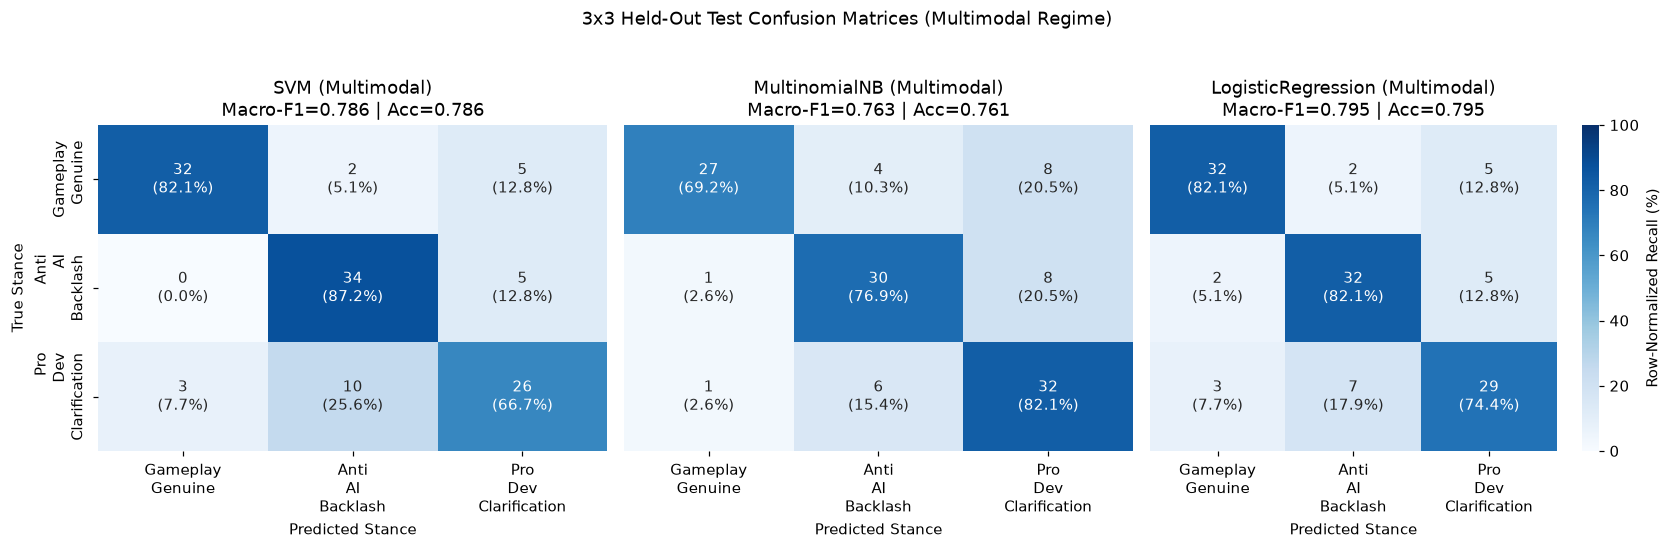

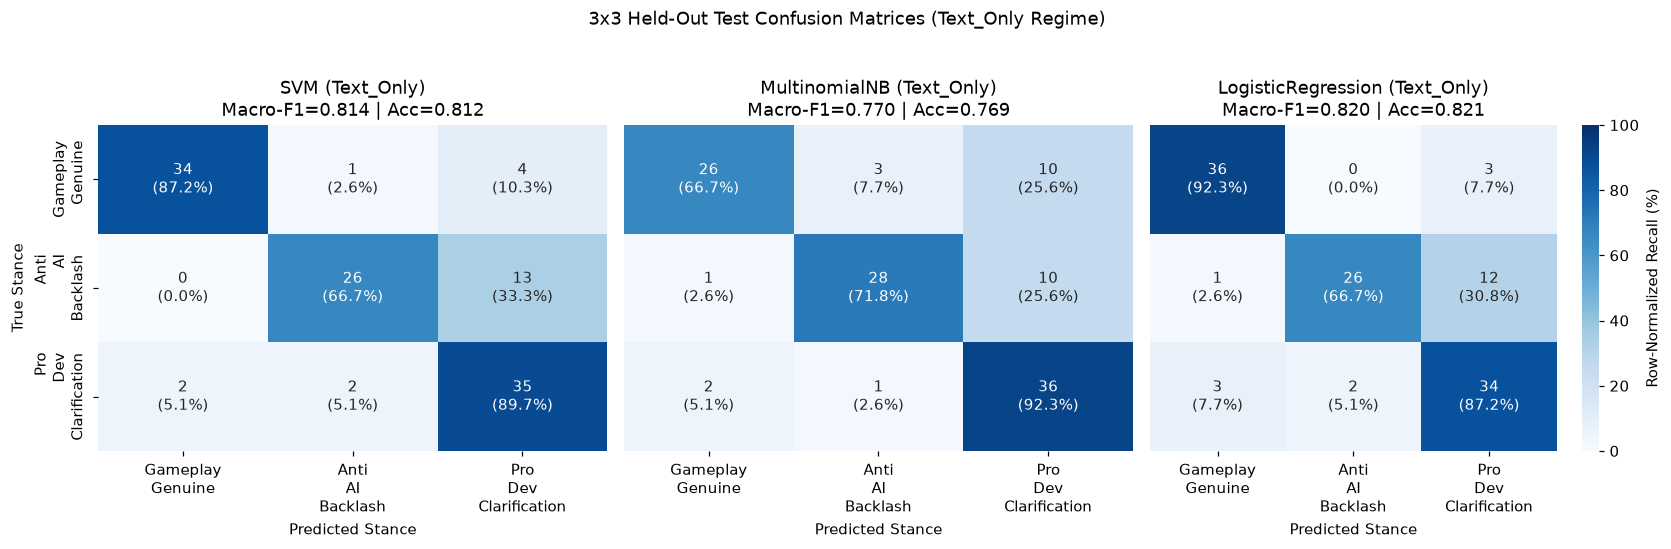

In [7]:
def compute_classification_metrics_table(
    ablation_results: dict[tuple[str, str], dict[str, Any]],
    class_names: list[str] = STANCE_CLASSES,
) -> pd.DataFrame:
    rows = []
    for (regime, model_name), res in ablation_results.items():
        y_true, y_pred = res["y_test"], res["y_pred"]
        per_class_f1 = f1_score(y_true, y_pred, labels=class_names, average=None, zero_division=0)
        row = {
            "Regime": regime,
            "Model": model_name,
            "CV_Macro_F1": round(float(res["cv_macro_f1"]), 4),
            "Accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "Macro_Precision": round(float(precision_score(y_true, y_pred, labels=class_names, average="macro", zero_division=0)), 4),
            "Macro_Recall": round(float(recall_score(y_true, y_pred, labels=class_names, average="macro", zero_division=0)), 4),
            "Macro_F1": round(float(f1_score(y_true, y_pred, labels=class_names, average="macro", zero_division=0)), 4),
            "Weighted_F1": round(float(f1_score(y_true, y_pred, labels=class_names, average="weighted", zero_division=0)), 4),
            "Cohens_Kappa": round(float(cohen_kappa_score(y_true, y_pred, labels=class_names)), 4),
            "MCC": round(float(matthews_corrcoef(y_true, y_pred)), 4),
        }
        for cls_name, cls_f1 in zip(class_names, per_class_f1):
            row[f"F1_{cls_name}"] = round(float(cls_f1), 4)
        rows.append(row)
    return pd.DataFrame(rows).sort_values(by=["Regime", "Macro_F1"], ascending=[True, False]).reset_index(drop=True)


def plot_confusion_matrices_grid(
    ablation_results: dict[tuple[str, str], dict[str, Any]],
    regime: str = "Multimodal",
    model_order: list[str] | None = None,
    class_names: list[str] = STANCE_CLASSES,
    figsize: tuple[float, float] = (15.5, 4.8),
) -> plt.Figure:
    models = model_order or ["SVM", "MultinomialNB", "LogisticRegression"]
    short_labels = [c.replace("_", "\n") for c in class_names]
    fig, axes = plt.subplots(1, len(models), figsize=figsize)
    if len(models) == 1:
        axes = [axes]

    for ax, m_name in zip(axes, models):
        res = ablation_results[(regime, m_name)]
        cm = confusion_matrix(res["y_test"], res["y_pred"], labels=class_names)
        cm_pct = (cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)) * 100.0
        annot = np.empty_like(cm, dtype=object)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                annot[i, j] = f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)"

        sns.heatmap(
            cm_pct, annot=annot, fmt="", cmap="Blues", vmin=0.0, vmax=100.0,
            xticklabels=short_labels, yticklabels=short_labels if ax is axes[0] else False,
            cbar=(ax is axes[-1]),
            cbar_kws={"label": "Row-Normalized Recall (%)"} if ax is axes[-1] else None,
            ax=ax,
        )
        ax.set_title(f"{m_name} ({regime})\nMacro-F1={res['test_macro_f1']:.3f} | Acc={res['test_accuracy']:.3f}")
        ax.set_xlabel("Predicted Stance")
        if ax is axes[0]:
            ax.set_ylabel("True Stance")

    fig.suptitle(f"3x3 Held-Out Test Confusion Matrices ({regime} Regime)", y=1.03, fontsize=12)
    fig.tight_layout()
    return fig


def mcnemar_pair_test(
    y_true: Iterable[Any],
    pred_a: Iterable[Any],
    pred_b: Iterable[Any],
) -> dict[str, Any]:
    yt = np.asarray(list(y_true))
    pa = np.asarray(list(pred_a))
    pb = np.asarray(list(pred_b))
    corr_a, corr_b = (pa == yt), (pb == yt)
    n11 = int(np.sum(corr_a & corr_b))
    b = int(np.sum(corr_a & ~corr_b))
    c = int(np.sum(~corr_a & corr_b))
    n00 = int(np.sum(~corr_a & ~corr_b))
    discordant = b + c

    if discordant == 0:
        return {"n11": n11, "b": b, "c": c, "n00": n00, "discordant": 0, "test_method": "Exact Binomial", "statistic": 0.0, "raw_p": 1.0}
    if discordant < 25:
        binom_res = stats.binomtest(min(b, c), n=discordant, p=0.5, alternative="two-sided")
        return {"n11": n11, "b": b, "c": c, "n00": n00, "discordant": discordant, "test_method": "Exact Binomial", "statistic": float(min(b, c)), "raw_p": float(binom_res.pvalue)}

    chi2_stat = ((abs(b - c) - 1.0) ** 2) / float(discordant)
    return {"n11": n11, "b": b, "c": c, "n00": n00, "discordant": discordant, "test_method": "Continuity-Corrected Chi2", "statistic": float(chi2_stat), "raw_p": float(stats.chi2.sf(chi2_stat, df=1))}


def compute_pairwise_mcnemar_table(
    ablation_results: dict[tuple[str, str], dict[str, Any]],
    regime: str = "Multimodal",
) -> pd.DataFrame:
    pair_list = [("SVM", "MultinomialNB"), ("SVM", "LogisticRegression"), ("LogisticRegression", "MultinomialNB")]
    rows, raw_ps = [], []
    for model_a, model_b in pair_list:
        res_a, res_b = ablation_results[(regime, model_a)], ablation_results[(regime, model_b)]
        m_out = mcnemar_pair_test(res_a["y_test"], res_a["y_pred"], res_b["y_pred"])
        raw_ps.append(m_out["raw_p"])
        rows.append({"regime": regime, "pair": f"{model_a} vs {model_b}", **m_out})
    holm_ps = holm_bonferroni_adjust(raw_ps)
    for i, row in enumerate(rows):
        row["holm_p"] = float(holm_ps[i])
        row["significant_0_05"] = bool(holm_ps[i] < 0.05)
    return pd.DataFrame(rows)


def generate_knowledge_synthesis_tables(
    corpus_df: pd.DataFrame,
    shock_summary_df: pd.DataFrame,
    divergence_summary: dict[str, Any],
    playtime_stats: dict[str, Any],
    metrics_table: pd.DataFrame,
) -> dict[str, pd.DataFrame]:
    shock_map = dict(zip(shock_summary_df["metric"], shock_summary_df["value"]))
    stance_counts = corpus_df["predicted_stance"].value_counts(normalize=True) * 100.0
    anti_ai_share = float(stance_counts.get("Anti_AI_Backlash", 0.0))
    pro_dev_share = float(stance_counts.get("Pro_Dev_Clarification", 0.0))
    gameplay_share = float(stance_counts.get("Gameplay_Genuine", 0.0))

    pt_df = playtime_stats["descriptive_table"].set_index("predicted_stance")
    anti_refund_pct = float(pt_df.loc["Anti_AI_Backlash", "refund_window_pct"])
    game_refund_pct = float(pt_df.loc["Gameplay_Genuine", "refund_window_pct"])
    anti_median_hrs = float(pt_df.loc["Anti_AI_Backlash", "median_hrs"])
    game_median_hrs = float(pt_df.loc["Gameplay_Genuine", "median_hrs"])

    anti_sub = corpus_df[corpus_df["predicted_stance"] == "Anti_AI_Backlash"]
    game_sub = corpus_df[corpus_df["predicted_stance"] == "Gameplay_Genuine"]
    anti_stopped_pct = float(100.0 * anti_sub["stopped_after_review"].mean())
    game_stopped_pct = float(100.0 * game_sub["stopped_after_review"].mean())
    anti_vel_mean = float(anti_sub["hourly_velocity"].mean())
    game_vel_mean = float(game_sub["hourly_velocity"].mean())

    mm_best = float(metrics_table[metrics_table["Regime"] == "Multimodal"]["Macro_F1"].max())
    tx_best = float(metrics_table[metrics_table["Regime"] == "Text_Only"]["Macro_F1"].max())
    f1_lift = mm_best - tx_best
    pro_dev_div_pct = float(divergence_summary.get("pro_dev_pos_vote_vader_neg_pct", np.nan))

    indie_studio_table = pd.DataFrame(
        [
            {"Signal_Dimension": "Baseline vs Peak Negative Rate", "Observed_Metric": f"{shock_map['Baseline_NegRate_PreT1']:.3f} -> {shock_map['Peak_NegRate']:.3f} (Delta={shock_map['Shock_Magnitude_DeltaNegRate']:.3f})", "Actionable_Studio_Guidance": "Monitor 6h negative rate against pre-controversy Wilson upper bound to trigger rapid FAQ response."},
            {"Signal_Dimension": "Onset Velocity & Excess Backlash", "Observed_Metric": f"Onset={shock_map['Onset_Velocity_From_T1_Hrs']}h post-T1 | Excess Neg={shock_map['Excess_Negative_Reviews']}", "Actionable_Studio_Guidance": "Issue factual scope clarification (e.g., exact asset/code footprint) within the first 24h before backlash peaks."},
            {"Signal_Dimension": "Post-Peak Recovery Half-Life", "Observed_Metric": f"t_1/2 = {shock_map['Recovery_Half_Life_Hrs']}h (lambda={shock_map['Decay_Lambda_Per_Hr']})", "Actionable_Studio_Guidance": "Track 6h exponential decay post-FAQ; sustained flat decay signals unresolved rumor persistence (Iteration 2 Module D)."},
            {"Signal_Dimension": "Corpus Stance Mix", "Observed_Metric": f"Gameplay={gameplay_share:.1f}%, Anti_AI={anti_ai_share:.1f}%, Pro_Dev={pro_dev_share:.1f}%", "Actionable_Studio_Guidance": "Separate ideological Anti_AI_Backlash from Gameplay_Genuine bug/balance feedback before prioritizing patches."},
            {"Signal_Dimension": "Counter-Wave Lexical Anger", "Observed_Metric": f"{pro_dev_div_pct:.1f}% of voted_up=True Pro_Dev reviews score VADER-negative", "Actionable_Studio_Guidance": "Do not mistake frustrated supporter language defending developers for negative sentiment in crisis dashboards."},
        ]
    )
    platform_moderator_table = pd.DataFrame(
        [
            {"Detection_Feature": "Playtime Refund-Window Concentration", "Observed_Metric": f"Anti_AI <2h={anti_refund_pct:.1f}% (median {anti_median_hrs:.2f}h) vs Gameplay <2h={game_refund_pct:.1f}% (median {game_median_hrs:.2f}h)", "Moderator_Rule_Guidance": "Combine playtime <2h and stopped_after_review flags with stance probabilities to flag non-gameplay off-topic spikes."},
            {"Detection_Feature": "Stopped-After-Review Ratio", "Observed_Metric": f"Anti_AI={anti_stopped_pct:.1f}% vs Gameplay={game_stopped_pct:.1f}%", "Moderator_Rule_Guidance": "Zero post-review playtime inside the refund window indicates drive-by protest reviews rather than ongoing play."},
            {"Detection_Feature": "Temporal Burst Velocity", "Observed_Metric": f"Mean 6h rolling velocity: Anti_AI={anti_vel_mean:.1f} vs Gameplay={game_vel_mean:.1f}", "Moderator_Rule_Guidance": "Pair PELT/CUSUM structural break alarms with rolling hourly_velocity spikes to isolate coordinated windows."},
            {"Detection_Feature": "VADER vs Vote Polarity Guardrail", "Observed_Metric": f"Pro_Dev positive-vote VADER-negative rate={pro_dev_div_pct:.1f}%", "Moderator_Rule_Guidance": "Avoid naive lexical sentiment filters that misclassify Pro_Dev_Clarification supporters using quoted backlash terms."},
            {"Detection_Feature": "Multimodal Ablation Gain", "Observed_Metric": f"Best Multimodal Macro-F1={mm_best:.4f} vs Text-Only={tx_best:.4f} (Delta={f1_lift:+.4f})", "Moderator_Rule_Guidance": "Behavioral metadata improves stance Macro-F1 over text alone and reinforces off-topic triage." if f1_lift >= 0 else "Text-Only leads in this run (likely because heuristic prelabels correlate with text); combine behavioral triage with verified gold_labels.csv."},
        ]
    )
    return {"indie_studio_crisis_table": indie_studio_table, "platform_moderator_table": platform_moderator_table}


metrics_tbl = compute_classification_metrics_table(ablation_out["results"])
print("Held-Out Test Classification Metrics (Text_Only vs Multimodal):")
print(metrics_tbl.to_string(index=False))

fig_cm_mm = plot_confusion_matrices_grid(ablation_out["results"], regime="Multimodal")
plt.show()
plt.close(fig_cm_mm)

fig_cm_tx = plot_confusion_matrices_grid(ablation_out["results"], regime="Text_Only")
plt.show()
plt.close(fig_cm_tx)

mcnemar_mm = compute_pairwise_mcnemar_table(ablation_out["results"], regime="Multimodal")
mcnemar_tx = compute_pairwise_mcnemar_table(ablation_out["results"], regime="Text_Only")
print("\nPairwise McNemar's Test (Multimodal Regime, Holm-Bonferroni Adjusted):")
print(mcnemar_mm.to_string(index=False))
print("\nPairwise McNemar's Test (Text_Only Regime, Holm-Bonferroni Adjusted):")
print(mcnemar_tx.to_string(index=False))

synth = generate_knowledge_synthesis_tables(corpus_pred_df, shock_summary_df, div_summary, playtime_stats, metrics_tbl)
print("\nActionable Synthesis - Indie Studio Crisis Communication:")
print(synth["indie_studio_crisis_table"].to_string(index=False))
print("\nActionable Synthesis - Platform Moderator Review-Bomb Detection:")
print(synth["platform_moderator_table"].to_string(index=False))